# Multivalent complex stability — metastable-Tm trend analysis

Standardized melting sweep across all rod-bridge dimer interfaces.

**Protocol (identical for every interface):** finite PBC box 30x28x28, Brownian thermostat gamma=5, burn-in 500k steps, production 150 samples x 15,000 steps, **3 replicate seeds**, all-from-bound (deep-well seed re-used at every temperature).

**Observable:** the *metastable* melting temperature Tm (bound-side; each T started from the fully-bound config). Absolute Tm carries a concentration/metastability offset (shared across designs, so it **cancels in design-to-design comparisons**); the defensible content is the **trends / orderings**.

Error bars: replicate samples pooled after subsampling each run to its effective independent count (N_eff = N/g, g = statistical inefficiency), with **bootstrap** uncertainty on the Tm crossing.

## Mechanism confirmation — force decomposition & tip preorganization

Targeted confirmation runs (2-bond, spacing = 4), each logging **every force's energy** and
the **bridge tip-tip distances** per production sample, let us decompose the per-bond
calorimetric energy and measure geometry directly. Data: `confirm_results/`.

**Result 1 — the melting shifts are NOT enthalpic.** The per-bond Morse (bridge) energy
slope d⟨E|n⟩/dn is **flat** across *both* scaffold rigidity (≈ −6.3 kT/bond, rod_bend 4→240)
and linker stiffness (≈ −5.2 to −6.3 kT/bond, chain_bend 4→40). Individual bonds are not
deepened by stiffness. ⚠️ **The total-PE "ΔH" trends reported earlier are therefore
unreliable as bond enthalpy** on these axes — they bundle how many bonds are populated at a
given T plus scaffold-bending energy, not the bond strength itself.

**Result 2 — the linker trend IS entropic / geometric (preorganization).** Using a
frame-invariant, distance-only metric (immune to rod tumbling, unlike tip-RMSF-vs-COM, which
was confounded and discarded), the tip-tip gap of an *unbound* bridge shrinks monotonically
with linker stiffness — mean 3.35 → 1.91 and spread 1.24 → 0.50 (chain_bend 4 → 40). A stiff
linker pre-holds its tip at the binding site, so binding costs ~**+2.7 k_B/bond less
configurational entropy** than a flexible one. The steep-then-saturating shape (big gain
4→10, diminishing after) mirrors the Tm plateau at high stiffness.

**Bottom line:** both scaffold rigidity and linker stiffness raise stability through an
**entropic/geometric preorganization** mechanism (flat bond enthalpy, reduced binding-entropy
penalty), not by strengthening bonds.

**Result 3 — preorganization is linker-specific.** The same unbound-gap metric vs *rod* bending stiffness is flat (3.58 → 3.33, spread ~1.2, rod_bend 4 → 240): the rigid scaffold does NOT pre-hold the tips. So the entropic preorganization driver is the linker, not the scaffold — panel (d) vs (c) on a shared axis makes the contrast explicit.

=== per-bond energy slope by force term (kT/bond) ===

-- scaffold rigidity (rod_bend) --
  rod_bend   bridge     bend       lj     fene  rodbond    graft   zalign
         4    -6.38    -1.18    -0.01     0.76    -1.02     0.12    -0.35
        20    -6.30    -1.80    -0.02     0.44    -1.25     0.25    -0.06
        80    -6.33    -1.25    -0.03     0.66    -1.16     0.04    -0.25
       240    -6.23    -1.00    -0.06     0.54    -1.33    -0.10    -0.47

-- linker stiffness (chain_bend) --
chain_bend   bridge     bend       lj     fene  rodbond    graft   zalign
         4    -6.33    -1.25    -0.03     0.66    -1.16     0.04    -0.25
        10    -5.35    -0.90     0.00     0.27     0.67    -0.17    -0.26
        20    -5.26    -0.54    -0.01     0.07     0.28    -0.10    -0.15
        40    -5.23    -1.63    -0.01     0.00     0.96    -0.02    -0.51

  --> 'bridge' (Morse bond enthalpy) is FLAT on both axes => the melting shift is
      NOT deeper bonds. Total-PE 'dH' trends are p

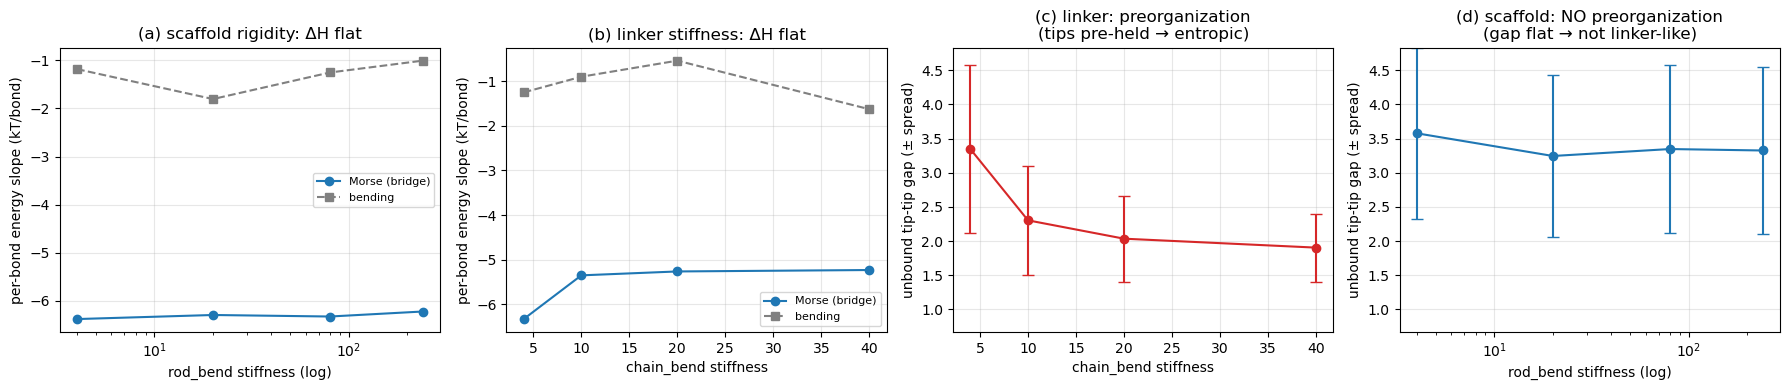

saved -> plots_robust/mechanism/mechanism.svg + mechanism.csv


In [5]:
# ===== Mechanism confirmation: per-force decomposition + tip preorganization =====
# Confirmation runs (2-bond, spacing=4; rigidity axis uses flexible linker, linker axis
# uses a rigid rod=80 scaffold). Each logged, per production sample: n_bound, EVERY
# force's potential energy, bridge tip-tip distances (+ tip positions / rod COMs).
# Data: confirm_results/{lightrun_rod*,linker_chain*}.npz
import os, csv, glob, numpy as np, matplotlib.pyplot as plt
CONFIRM = "confirm_results"; MROOT = os.path.join("plots_robust", "mechanism")
os.makedirs(MROOT, exist_ok=True)
TERMS = ["bridge", "bend", "lj", "fene", "rodbond", "graft", "zalign"]
RBIND = 1.4

def per_bond_slopes(d, mn=4):
    """Calorimetric per-bond energy slope d<E|n>/dn (kT/bond) for each force term,
    averaged over the sampled temperatures. 'bridge' = Morse bond enthalpy."""
    Ts = d["temps"]; out = {}
    for term in TERMS:
        sl = []
        for T in Ts:
            n = d[f"T{T}_n"]; E = d[f"T{T}_E_{term}"]; xs = []; ys = []
            for nv in sorted(set(n.tolist())):
                m = n == nv
                if m.sum() >= mn:
                    xs.append(nv); ys.append(np.nanmean(E[m]))
            if len(xs) >= 2:
                sl.append(np.polyfit(xs, ys, 1)[0])
        out[term] = float(np.mean(sl)) if sl else np.nan
    return out

def unbound_gap(d):
    """Frame-invariant preorganization metric: tip-tip distance of UNBOUND bridge pairs
    (pooled over T). Distance-only => immune to rod tumbling (unlike RMSF vs COM)."""
    gaps = []
    for T in d["temps"]:
        dist = d[f"T{T}_dist"]
        for p in range(dist.shape[1]):
            col = dist[:, p]; gaps.extend(col[col > RBIND].tolist())
    gaps = np.array(gaps)
    return gaps.mean(), gaps.std(), len(gaps)

# ---- load both confirmation sweeps ----
rig = {int(np.load(f, allow_pickle=True)["rod"]): np.load(f, allow_pickle=True)
       for f in glob.glob(os.path.join(CONFIRM, "lightrun_rod*.npz"))}
lnk = {int(np.load(f, allow_pickle=True)["chain"]): np.load(f, allow_pickle=True)
       for f in glob.glob(os.path.join(CONFIRM, "linker_chain*.npz"))}
rig_k = sorted(rig); lnk_k = sorted(lnk)

print("=== per-bond energy slope by force term (kT/bond) ===")
for name, data, keys, xlab in [("scaffold rigidity (rod_bend)", rig, rig_k, "rod_bend"),
                               ("linker stiffness (chain_bend)", lnk, lnk_k, "chain_bend")]:
    print(f"\n-- {name} --")
    print(f"{xlab:>10} " + " ".join(f"{t:>8}" for t in TERMS))
    for k in keys:
        s = per_bond_slopes(data[k])
        print(f"{k:>10} " + " ".join(f"{s[t]:>8.2f}" for t in TERMS))
print("\n  --> 'bridge' (Morse bond enthalpy) is FLAT on both axes => the melting shift is")
print("      NOT deeper bonds. Total-PE 'dH' trends are population/bending bookkeeping, not enthalpy.\n")

print("=== unbound tip-tip gap (geometric preorganization) ===")
gap_m = {}; gap_s = {}      # linker axis
for k in lnk_k:
    gm, gs, nu = unbound_gap(lnk[k]); gap_m[k] = gm; gap_s[k] = gs
rgap_m = {}; rgap_s = {}    # rigidity axis
for k in rig_k:
    gm, gs, nu = unbound_gap(rig[k]); rgap_m[k] = gm; rgap_s[k] = gs
print(f"-- linker stiffness (chain_bend) --")
print(f"{'chain_bend':>10} {'gap_mean':>9} {'gap_std':>8} {'dS_config(k_B, rel k=4)':>24}")
ref = gap_s[lnk_k[0]]
for k in lnk_k:
    print(f"{k:>10} {gap_m[k]:>9.3f} {gap_s[k]:>8.3f} {3*np.log(ref/gap_s[k]):>24.2f}")
print(f"-- scaffold rigidity (rod_bend) --")
print(f"{'rod_bend':>10} {'gap_mean':>9} {'gap_std':>8} {'dS_config(k_B, rel k=4)':>24}")
rref = rgap_s[rig_k[0]]
for k in rig_k:
    print(f"{k:>10} {rgap_m[k]:>9.3f} {rgap_s[k]:>8.3f} {3*np.log(rref/rgap_s[k]):>24.2f}")
print("  --> LINKER stiffness collapses the unbound gap (tips pre-held => entropic, ~+2.7 k_B/bond).")
print("      ROD stiffness leaves the gap FLAT => preorganization is linker-specific, not scaffold.\n")

# ---- figure: Morse flat (both axes) + preorganization (linker vs rod) ----
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
ax[0].plot(rig_k, [per_bond_slopes(rig[k])["bridge"] for k in rig_k], "o-", label="Morse (bridge)")
ax[0].plot(rig_k, [per_bond_slopes(rig[k])["bend"] for k in rig_k], "s--", color="gray", label="bending")
ax[0].set_xscale("log"); ax[0].set_xlabel("rod_bend stiffness (log)")
ax[0].set_ylabel("per-bond energy slope (kT/bond)"); ax[0].set_title("(a) scaffold rigidity: ΔH flat")
ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
ax[1].plot(lnk_k, [per_bond_slopes(lnk[k])["bridge"] for k in lnk_k], "o-", label="Morse (bridge)")
ax[1].plot(lnk_k, [per_bond_slopes(lnk[k])["bend"] for k in lnk_k], "s--", color="gray", label="bending")
ax[1].set_xlabel("chain_bend stiffness"); ax[1].set_ylabel("per-bond energy slope (kT/bond)")
ax[1].set_title("(b) linker stiffness: ΔH flat"); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)
ax[2].errorbar(lnk_k, [gap_m[k] for k in lnk_k], yerr=[gap_s[k] for k in lnk_k],
               marker="o", capsize=4, color="C3")
ax[2].set_xlabel("chain_bend stiffness"); ax[2].set_ylabel("unbound tip-tip gap (± spread)")
ax[2].set_title("(c) linker: preorganization\n(tips pre-held → entropic)"); ax[2].grid(alpha=.3)
ax[3].errorbar(rig_k, [rgap_m[k] for k in rig_k], yerr=[rgap_s[k] for k in rig_k],
               marker="o", capsize=4, color="C0")
ax[3].set_xscale("log"); ax[3].set_xlabel("rod_bend stiffness (log)")
ax[3].set_ylabel("unbound tip-tip gap (± spread)")
ax[3].set_title("(d) scaffold: NO preorganization\n(gap flat → not linker-like)"); ax[3].grid(alpha=.3)
_ylo = min(min(gap_m.values()) - max(gap_s.values()), min(rgap_m.values()) - max(rgap_s.values()))
_yhi = max(max(gap_m.values()) + max(gap_s.values()), max(rgap_m.values()) + max(rgap_s.values()))
ax[2].set_ylim(_ylo, _yhi); ax[3].set_ylim(_ylo, _yhi)   # shared scale for honest comparison
fig.tight_layout(); fig.savefig(os.path.join(MROOT, "mechanism.svg")); plt.show()

# ---- CSV behind the figure ----
with open(os.path.join(MROOT, "mechanism.csv"), "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["axis", "stiffness", "dH_bridge_perbond", "dH_bend_perbond",
                "unbound_gap_mean", "unbound_gap_std"])
    for k in rig_k:
        s = per_bond_slopes(rig[k])
        w.writerow(["rigidity", k, round(s["bridge"], 3), round(s["bend"], 3),
                    round(rgap_m[k], 3), round(rgap_s[k], 3)])
    for k in lnk_k:
        s = per_bond_slopes(lnk[k])
        w.writerow(["linker", k, round(s["bridge"], 3), round(s["bend"], 3),
                    round(gap_m[k], 3), round(gap_s[k], 3)])
print(f"saved -> {MROOT}/mechanism.svg + mechanism.csv")


### Panel C — gap distributions at a single temperature (kT = 2.0)

Overlaid density histogram of the unbound tip-tip gap at each `chain_bend` (rod fixed = 80), **at kT = 2.0** so thermal amplitude and the unbound-frame fraction are held fixed across series (pooling temperatures would confound the comparison). The preorganization trend holds within every fixed T (mean gap 3.90→1.95, σ 1.26→0.55 at kT=2.0). Writes `panelC_histograms.svg` + `panelC_histograms_raw.csv` (chain_bend, temperature, pair_index, tip_gap) + `panelC_histograms_binned.csv` (bin edges/centers + per-series density).

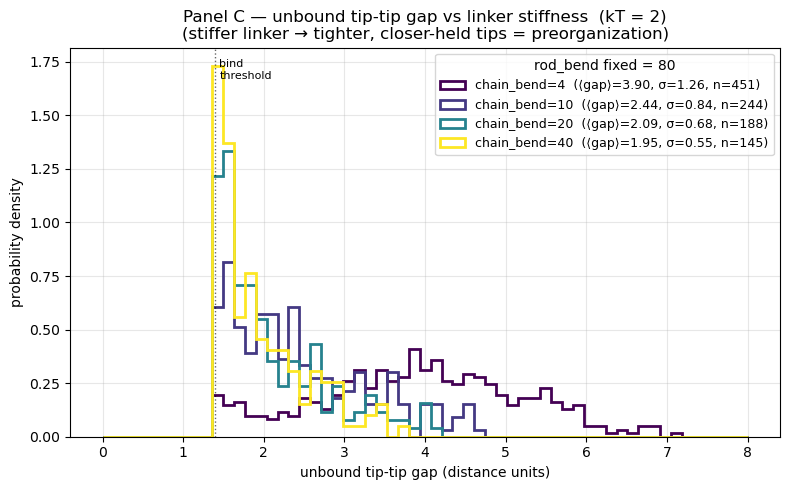

saved (kT=2) -> panelC_histograms.svg  +  panelC_histograms_raw.csv  +  panelC_histograms_binned.csv
raw rows per chain_bend: {4: 451, 10: 244, 20: 188, 40: 145}


In [6]:
# ===== Panel C as overlaid histograms: unbound tip-tip gap vs linker stiffness =====
# Single plot, one step-histogram per chain_bend (rod fixed = 80), at a SINGLE temperature
# (TSEL) so thermal fluctuation and the unbound-frame fraction are held fixed across series
# -- otherwise pooling temperatures confounds the comparison. Saves the figure plus TWO csv
# files: raw per-observation gaps (long format) and binned densities (what the bars draw).
import os, csv, glob, numpy as np, matplotlib.pyplot as plt
CONFIRM = "confirm_results"; MROOT = os.path.join("plots_robust", "mechanism")
os.makedirs(MROOT, exist_ok=True)
RBIND = 1.4
TSEL = 2.0                                          # single temperature for the comparison
BINS = np.linspace(0, 8, 60)                        # fixed bin edges, shared by all series

def unbound_gaps(d, Tsel=TSEL):
    """Unbound (gap > RBIND) tip-tip distances at the single temperature Tsel, long format."""
    rows = []
    T = min(d["temps"], key=lambda t: abs(float(t) - Tsel))   # nearest logged temperature
    dist = d[f"T{T}_dist"]
    for p in range(dist.shape[1]):
        col = dist[:, p]
        for g in col[col > RBIND]:
            rows.append((float(T), int(p), float(g)))
    return rows

files = sorted(glob.glob(os.path.join(CONFIRM, "linker_chain*.npz")),
               key=lambda f: int(f.split("chain")[1].split(".")[0]))
ks = [int(np.load(f, allow_pickle=True)["chain"]) for f in files]
raw = {}                                            # k -> list[(T, pair, gap)]
for f, k in zip(files, ks):
    raw[k] = unbound_gaps(np.load(f, allow_pickle=True))

# ---- figure ----
fig, axp = plt.subplots(figsize=(8, 5)); cmap = plt.cm.viridis
dens = {}
for k in ks:
    g = np.array([r[2] for r in raw[k]])
    col = cmap((k - min(ks)) / (max(ks) - min(ks) + 1e-9))
    h, _ = np.histogram(g, bins=BINS, density=True); dens[k] = h
    axp.hist(g, bins=BINS, density=True, histtype="step", lw=2, color=col,
             label=f"chain_bend={k}  (⟨gap⟩={g.mean():.2f}, σ={g.std():.2f}, n={len(g)})")
axp.axvline(RBIND, ls=":", color="k", alpha=.6, lw=1)
axp.text(RBIND + .05, axp.get_ylim()[1] * .92, "bind\nthreshold", fontsize=8)
axp.set_xlabel("unbound tip-tip gap (distance units)"); axp.set_ylabel("probability density")
axp.set_title(f"Panel C — unbound tip-tip gap vs linker stiffness  (kT = {TSEL:g})\n"
              "(stiffer linker → tighter, closer-held tips = preorganization)")
axp.legend(fontsize=9, title="rod_bend fixed = 80"); axp.grid(alpha=.3)
fig.tight_layout(); fig.savefig(os.path.join(MROOT, "panelC_histograms.svg")); plt.show()

# ---- CSV 1: raw per-observation gaps (the true underlying data) ----
with open(os.path.join(MROOT, "panelC_histograms_raw.csv"), "w", newline="") as fh:
    w = csv.writer(fh); w.writerow(["chain_bend", "temperature", "pair_index", "tip_gap"])
    for k in ks:
        for T, p, g in raw[k]:
            w.writerow([k, T, p, round(g, 5)])

# ---- CSV 2: binned densities (what the histogram bars draw) ----
centers = 0.5 * (BINS[:-1] + BINS[1:])
with open(os.path.join(MROOT, "panelC_histograms_binned.csv"), "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["bin_left", "bin_right", "bin_center"] + [f"density_chain{k}" for k in ks])
    for i in range(len(centers)):
        w.writerow([round(BINS[i], 4), round(BINS[i + 1], 4), round(centers[i], 4)]
                   + [round(dens[k][i], 6) for k in ks])

print(f"saved (kT={TSEL:g}) -> panelC_histograms.svg  +  panelC_histograms_raw.csv  +  panelC_histograms_binned.csv")
print("raw rows per chain_bend:", {k: len(raw[k]) for k in ks})


## Scaffold rigidity — anchor-site registration (mechanism)

Probes *why* scaffold rigidity raises Tm, from the rerun GSD trajectories (rigidity series rod_bend 4/20/80/240 (complete), spacing 4). Anchors fixed by the sp4 layout: rod0=[9,13], rod1=[31,35].

**Clean metric — intra-rod anchor spacing** (one rod's own two anchors): rigidity both corrects the mean (floppy rod *sags* to 3.66 vs design 4.0; rigid holds ~4.15) and tightens the spread (σ 0.45→0.30). The variance drop is the entropy of localization paid on binding: ΔS_reg ≈ k_B·ln(σ_floppy/σ_rigid) ≈ **+0.4 k_B per DOF**, robust across kT=1.25/1.5/1.75. Because binding the 2nd+ bond requires localizing the scaffold into a narrow, correctly-centered geometry, a stiffer scaffold pre-pays that entropy (higher effective concentration of the partner site) → more favorable ΔS → higher Tm. Per-bond ΔH is unchanged, so this is a purely entropic/avidity (valency) effect.

**Confounded metric — cross-rod transverse offset** (reported in the CSV but not used for the conclusion): dominated by the two rods' relative rigid-body sliding/tilting (mean ~3.3), so it shows no clean trend. A rod-frame-aligned version is deferred to the full run.

Outputs: `plots_robust/mechanism/registration.svg` (mean±σ, spacing histograms, ΔS_reg vs T), `registration_raw.csv` (per-frame: rod_bend, temperature, rep, metric, value), `registration_summary.csv`. NOTE: rod_bend=240 (VeryRigid) auto-includes once its GSD lands.

**Error bars = replicates.** All metrics are computed per replicate (seeds 11/22/33); plotted points are mean ± s.d. across the 3 reps. The spread σ separates cleanly: σ=0.44±0.04 (rod_bend 4) vs 0.31±0.01 (rod_bend 20/80) at kT=1.5, and ΔS_reg=0.37±0.03 k_B (rigid) vs 0.00±0.10 (floppy) — the registration gain is well outside replicate scatter.

**4-point series (complete).** rod_bend=240 is now included and confirms **saturation**: σ=0.30 and ΔS_reg=0.37 k_B are identical at rod_bend 80 and 240, while the mean spacing keeps creeping toward design (4.15→4.18 at kT=1.5). So the registration preorganization is essentially maxed out by rod_bend≈80 — matching the diminishing-returns/plateau seen in Tm at high scaffold rigidity.

rod_bend with GSD data: [4, 20, 80, 240] | reps: {4: [0, 1, 2], 20: [0, 1, 2], 80: [0, 1, 2], 240: [0, 1, 2]}

T=1.25: rod_bend     intra_mean    intra_sigma(spread)      dS_reg(k_B)
               4    3.714±0.074      0.382±0.042          0.01±0.11
              20    4.055±0.024      0.278±0.003          0.32±0.01
              80    4.124±0.013      0.276±0.006          0.32±0.02
             240    4.142±0.013      0.276±0.007          0.32±0.02

T=1.5: rod_bend     intra_mean    intra_sigma(spread)      dS_reg(k_B)
               4    3.660±0.083      0.436±0.044          0.01±0.10
              20    4.066±0.029      0.305±0.003          0.36±0.01
              80    4.151±0.017      0.301±0.009          0.37±0.03
             240    4.175±0.017      0.301±0.009          0.37±0.03

T=1.75: rod_bend     intra_mean    intra_sigma(spread)      dS_reg(k_B)
               4    3.628±0.088      0.474±0.046          0.00±0.10
              20    4.080±0.030      0.328±0.003          0.

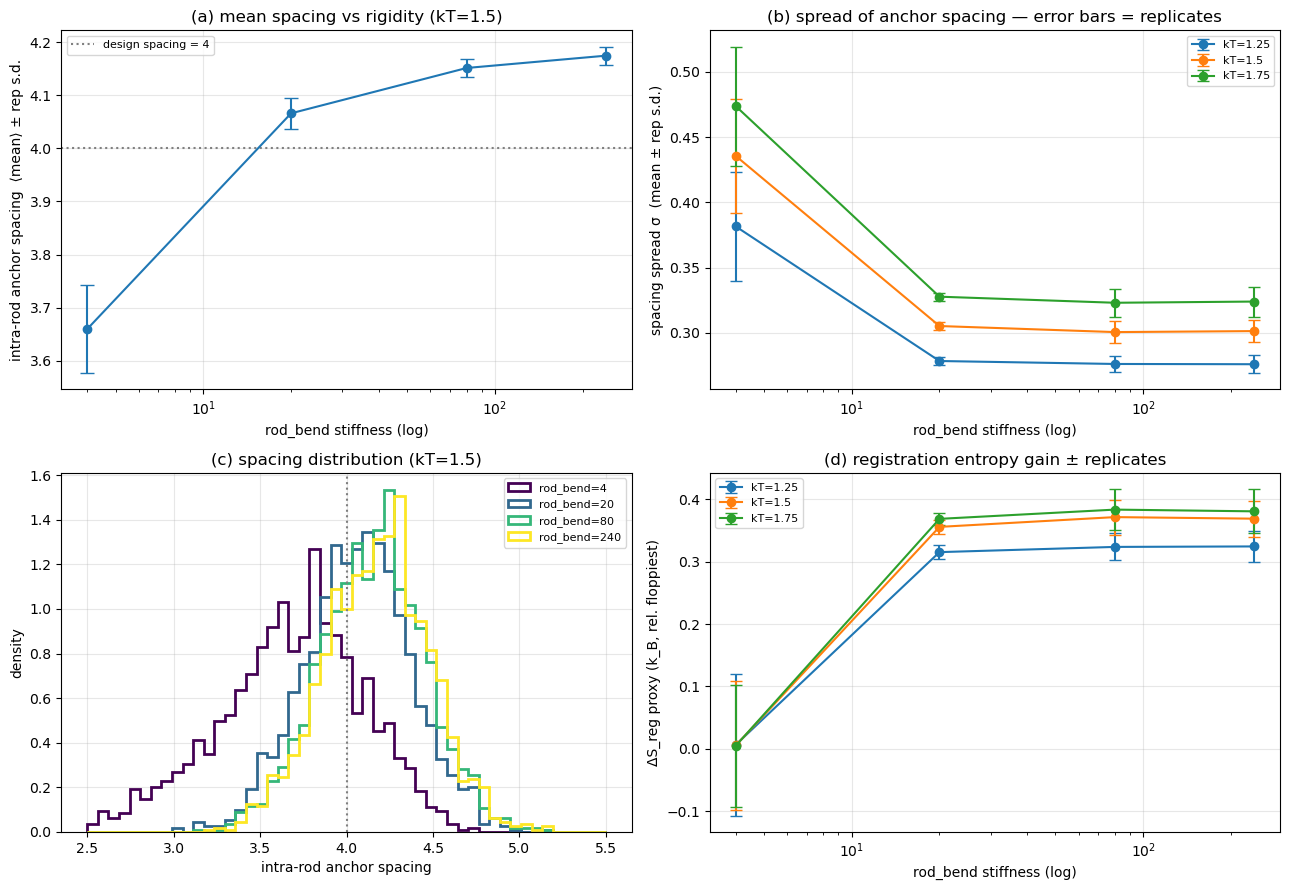


saved -> registration.svg + registration_raw.csv (43200 rows) + registration_summary.csv


In [7]:
# ===== Scaffold rigidity mechanism: anchor-site REGISTRATION (from rerun GSD) =====
# Rigidity series (rod_bend 4/20/80[/240]), spacing = 4. Anchor tags are fixed by the sp4
# layout: rod0 = [9,13], rod1 = [31,35]. Registered cross-rod pairs = (9,31),(13,35);
# intra-rod anchor spacing = (9,13),(31,35). For each rod stiffness, at a FIXED temperature,
# metrics are computed PER REPLICATE (seeds 11/22/33); error bars = std across replicates.
#   - intra-rod anchor spacing  (clean scaffold-bending readout)  -> mean, spread(sigma)
#   - cross-rod transverse (x,y) misregistration  (CONFOUNDED by rod rigid-body motion)
# dS_reg ~ k_B*ln(sigma_floppy/sigma): entropy of localization paid on binding.
import os, re, csv, glob, numpy as np, matplotlib.pyplot as plt
import gsd.hoomd
MROOT = os.path.join("plots_robust", "mechanism"); os.makedirs(MROOT, exist_ok=True)
SP = 4
STEMS = [(4, "Base"), (20, "ModerateScaffold"),
         (80, "RigidScaffold"), (240, "VeryRigidScaffold")]
CROSS = [(9, 31), (13, 35)]        # registered cross-rod pairs (align in x,y)
INTRA = [(9, 13), (31, 35)]        # intra-rod anchor spacing (rod0, rod1)
TEMPS = [1.25, 1.5, 1.75]
TPLOT = 1.5                         # single temperature for the mean/histogram panels

def per_rep(stem, T):
    """{rep: dict(intra=array, trans=array)} pooled over the two anchor pairs within a rep."""
    out = {}
    for f in glob.glob(f"gsd_results/gsd_{stem}_sp{SP}_rep*_T{T:g}.gsd"):
        m = re.search(r"_rep(\d+)_", os.path.basename(f)); rep = int(m.group(1)) if m else -1
        try: t = gsd.hoomd.open(f, "r")
        except Exception: continue
        iv = []; tv = []
        for fr in t:
            p = np.asarray(fr.particles.position)
            for a, b in INTRA: iv.append(float(np.linalg.norm(p[a] - p[b])))
            for a0, a1 in CROSS:
                d = p[a1] - p[a0]; tv.append(float(np.hypot(d[0], d[1])))
        t.close()
        out.setdefault(rep, {"intra": [], "trans": []})
        out[rep]["intra"] += iv; out[rep]["trans"] += tv
    return {r: {k: np.array(v) for k, v in d.items()} for r, d in out.items()}

# ---- gather per-rep stats; S[rb][T] = dict of arrays over reps ----
S = {}; have = []; raw_rows = []
for rb, stem in STEMS:
    perT = {}
    for T in TEMPS:
        pr = per_rep(stem, T)
        if not pr: continue
        reps = sorted(pr)
        isig = np.array([pr[r]["intra"].std() for r in reps])
        imean = np.array([pr[r]["intra"].mean() for r in reps])
        tsig = np.array([pr[r]["trans"].std() for r in reps])
        perT[T] = dict(reps=reps, isig=isig, imean=imean, tsig=tsig)
        for r in reps:
            for v in pr[r]["intra"]: raw_rows.append((rb, T, r, "intra_spacing", round(float(v), 5)))
            for v in pr[r]["trans"]: raw_rows.append((rb, T, r, "transverse_misreg", round(float(v), 5)))
    if perT: S[rb] = perT; have.append(rb)
rbs = have
print("rod_bend with GSD data:", rbs, "| reps:", {rb: S[rb][TPLOT]["reps"] for rb in rbs if TPLOT in S[rb]})

def agg(rb, T, key):
    a = S[rb][T][key]; return float(a.mean()), float(a.std())   # mean, std across reps

# ---- dS_reg per rep (relative to floppiest's per-rep mean sigma) ----
def dS_stats(rb, T):
    base = S[rbs[0]][T]["isig"].mean()
    vals = np.log(base / S[rb][T]["isig"])
    return float(vals.mean()), float(vals.std())

for T in TEMPS:
    if not all(T in S[rb] for rb in rbs): continue
    print(f"\nT={T}: {'rod_bend':>8} {'intra_mean':>14} {'intra_sigma(spread)':>22} {'dS_reg(k_B)':>16}")
    for rb in rbs:
        mm, me = agg(rb, T, "imean"); sm, se = agg(rb, T, "isig"); dm, de = dS_stats(rb, T)
        print(f"        {rb:>8} {mm:>8.3f}±{me:<5.3f} {sm:>10.3f}±{se:<6.3f}      {dm:>7.2f}±{de:.2f}")

# ---- figure: 2x2 ----
fig, ax = plt.subplots(2, 2, figsize=(13, 9)); ax = ax.ravel()
# (a) mean spacing +/- rep error, at TPLOT
mm = [agg(rb, TPLOT, "imean")[0] for rb in rbs]; me = [agg(rb, TPLOT, "imean")[1] for rb in rbs]
ax[0].errorbar(rbs, mm, yerr=me, marker="o", capsize=5, color="C0")
ax[0].axhline(SP, ls=":", color="gray", label=f"design spacing = {SP}")
ax[0].set_xscale("log"); ax[0].set_xlabel("rod_bend stiffness (log)")
ax[0].set_ylabel("intra-rod anchor spacing  ⟨mean⟩ ± rep s.d.")
ax[0].set_title(f"(a) mean spacing vs rigidity (kT={TPLOT})"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
# (b) SPREAD sigma +/- rep error, across T  <-- the requested error bars
for T in TEMPS:
    if not all(T in S[rb] for rb in rbs): continue
    sm = [agg(rb, T, "isig")[0] for rb in rbs]; se = [agg(rb, T, "isig")[1] for rb in rbs]
    ax[1].errorbar(rbs, sm, yerr=se, marker="o", capsize=4, label=f"kT={T}")
ax[1].set_xscale("log"); ax[1].set_xlabel("rod_bend stiffness (log)")
ax[1].set_ylabel("spacing spread σ  (mean ± rep s.d.)")
ax[1].set_title("(b) spread of anchor spacing — error bars = replicates"); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)
# (c) histograms at TPLOT (pooled reps) for context
bins = np.linspace(2.5, 5.5, 50); cmap = plt.cm.viridis
for rb in rbs:
    g = np.array([v for (b_, t_, r_, k_, v) in raw_rows if b_ == rb and t_ == TPLOT and k_ == "intra_spacing"])
    ax[2].hist(g, bins=bins, density=True, histtype="step", lw=2,
               color=cmap(rbs.index(rb) / max(len(rbs) - 1, 1)), label=f"rod_bend={rb}")
ax[2].axvline(SP, ls=":", color="gray"); ax[2].set_xlabel("intra-rod anchor spacing")
ax[2].set_ylabel("density"); ax[2].set_title(f"(c) spacing distribution (kT={TPLOT})")
ax[2].legend(fontsize=8); ax[2].grid(alpha=.3)
# (d) dS_reg +/- rep error, across T
for T in TEMPS:
    if not all(T in S[rb] for rb in rbs): continue
    dm = [dS_stats(rb, T)[0] for rb in rbs]; de = [dS_stats(rb, T)[1] for rb in rbs]
    ax[3].errorbar(rbs, dm, yerr=de, marker="o", capsize=4, label=f"kT={T}")
ax[3].set_xscale("log"); ax[3].set_xlabel("rod_bend stiffness (log)")
ax[3].set_ylabel("ΔS_reg proxy (k_B, rel. floppiest)")
ax[3].set_title("(d) registration entropy gain ± replicates"); ax[3].legend(fontsize=8); ax[3].grid(alpha=.3)
fig.tight_layout(); fig.savefig(os.path.join(MROOT, "registration.svg")); plt.show()

# ---- CSVs ----
with open(os.path.join(MROOT, "registration_raw.csv"), "w", newline="") as fh:
    w = csv.writer(fh); w.writerow(["rod_bend", "temperature", "rep", "metric", "value"]); w.writerows(raw_rows)
with open(os.path.join(MROOT, "registration_summary.csv"), "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["rod_bend", "temperature", "n_reps", "intra_mean", "intra_mean_reperr",
                "intra_sigma", "intra_sigma_reperr", "dS_reg_kB", "dS_reg_reperr",
                "transverse_sigma_confounded", "transverse_sigma_reperr"])
    for rb in rbs:
        for T in TEMPS:
            if T not in S[rb]: continue
            mm, me = agg(rb, T, "imean"); sm, se = agg(rb, T, "isig")
            tm, te = agg(rb, T, "tsig"); dm, de = dS_stats(rb, T)
            w.writerow([rb, T, len(S[rb][T]["reps"]), round(mm, 4), round(me, 4),
                        round(sm, 4), round(se, 4), round(dm, 4), round(de, 4),
                        round(tm, 4), round(te, 4)])
print(f"\nsaved -> registration.svg + registration_raw.csv ({len(raw_rows)} rows) + registration_summary.csv")


## b–f thermodynamic panels on the v2 rerun data

Regenerated from `std_results_v2/` (the standardized rerun: 300 samples, uniform ≤2.0 ladder, 3 seeds) into `plots_robust_v2/{b..f}/`. The original `plots_robust/` (old data) is left intact for comparison. All 95 interfaces have a crossable Tm with none needing upward extension.

loaded 97 interfaces; 97 have a crossable Tm


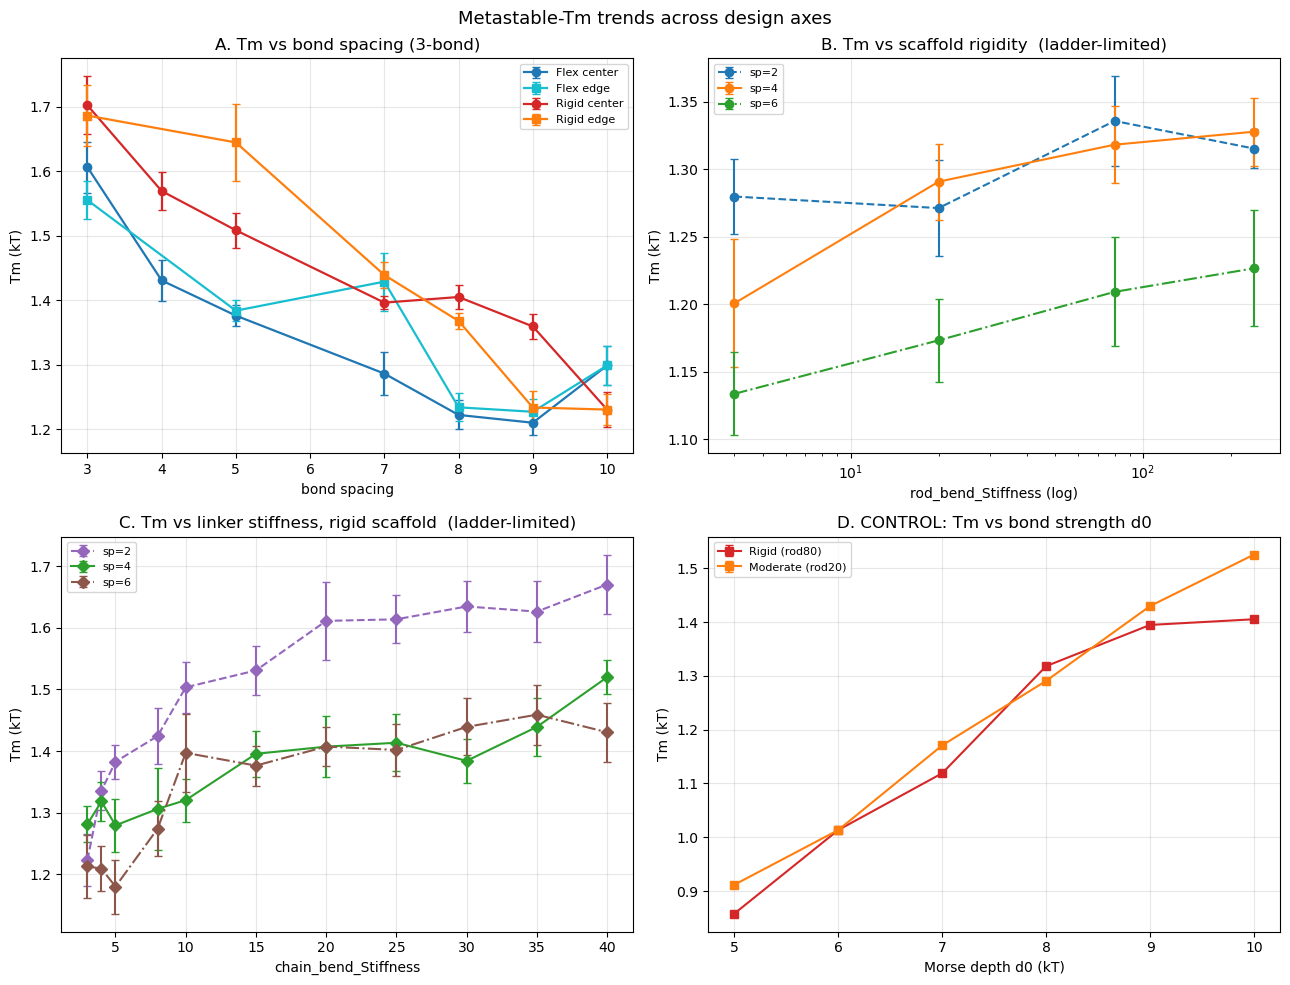

0 interfaces need UPWARD T-extension (B_mean stays > 1.5 across their whole ladder)

stem                                                  sp  d0  Tmax  B@Tmax


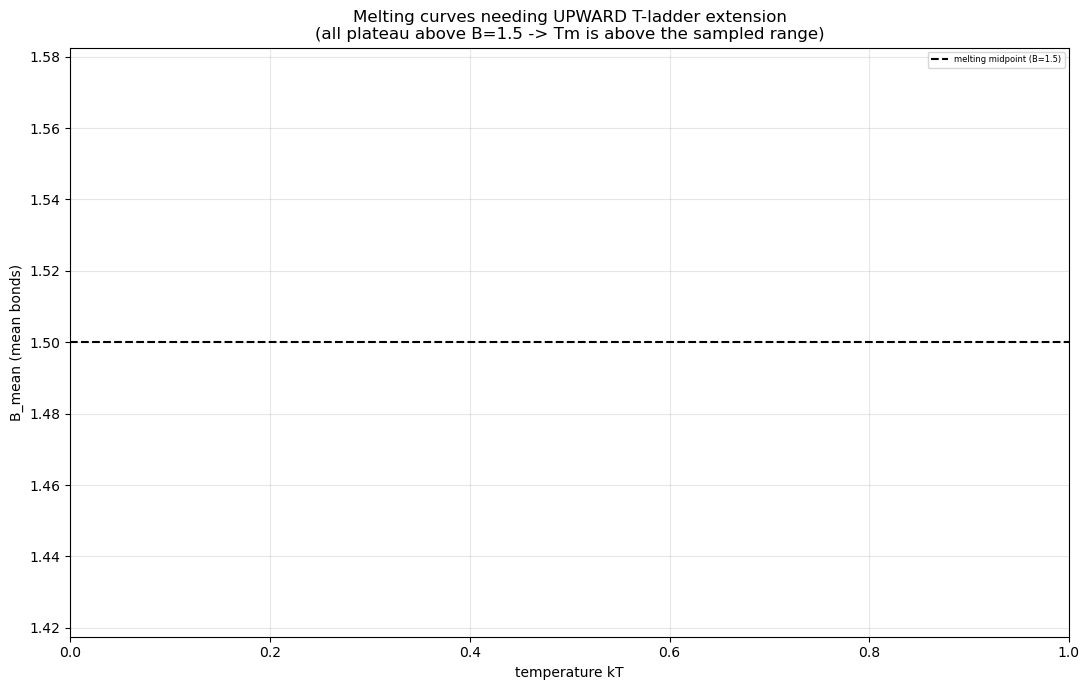

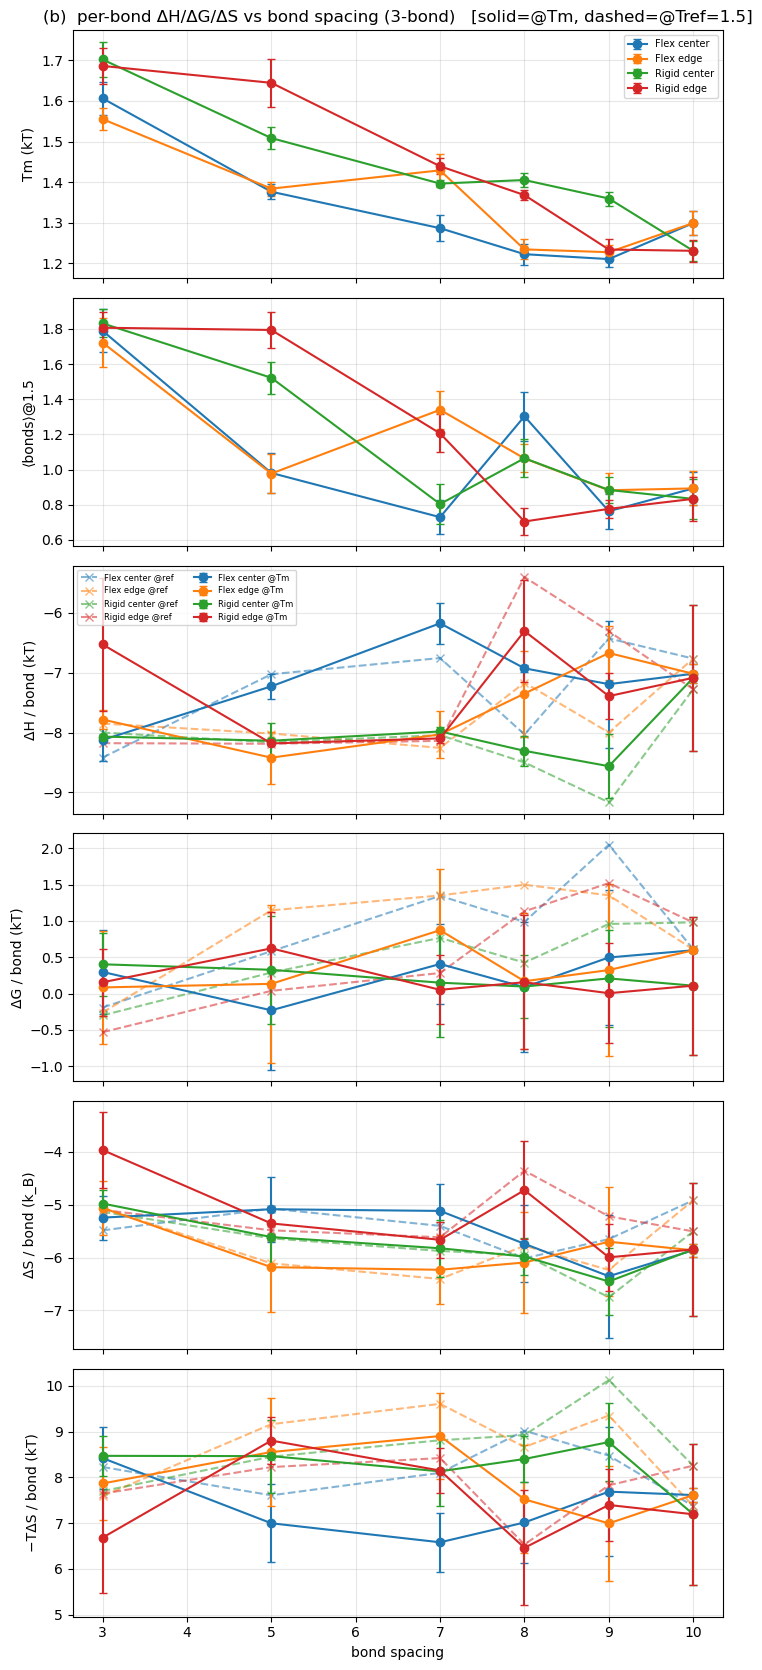

  (b) saved (24 rows)  @Tm + @ref


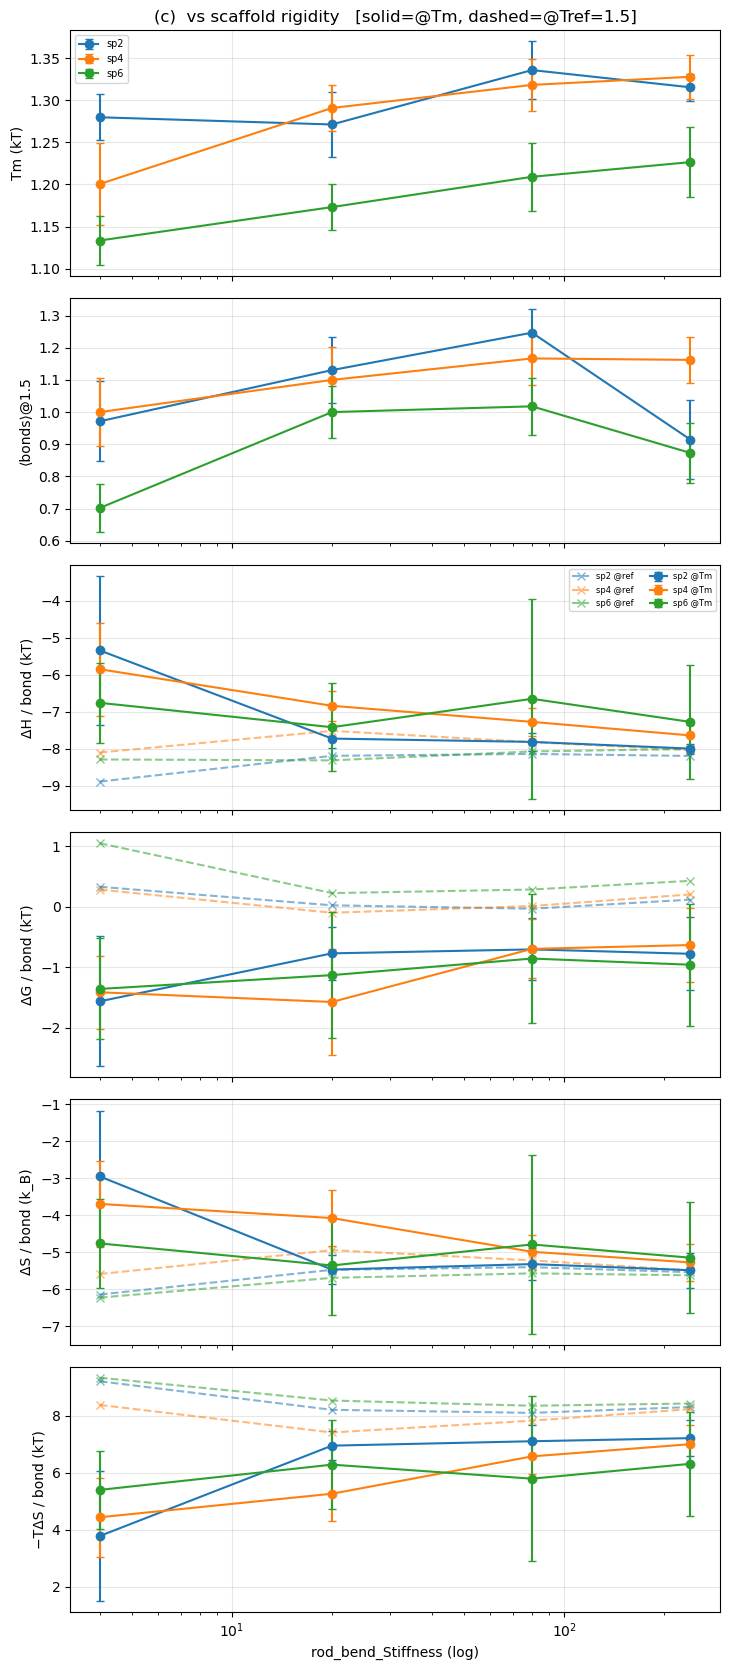

  (c) saved (12 rows)  @Tm + @ref


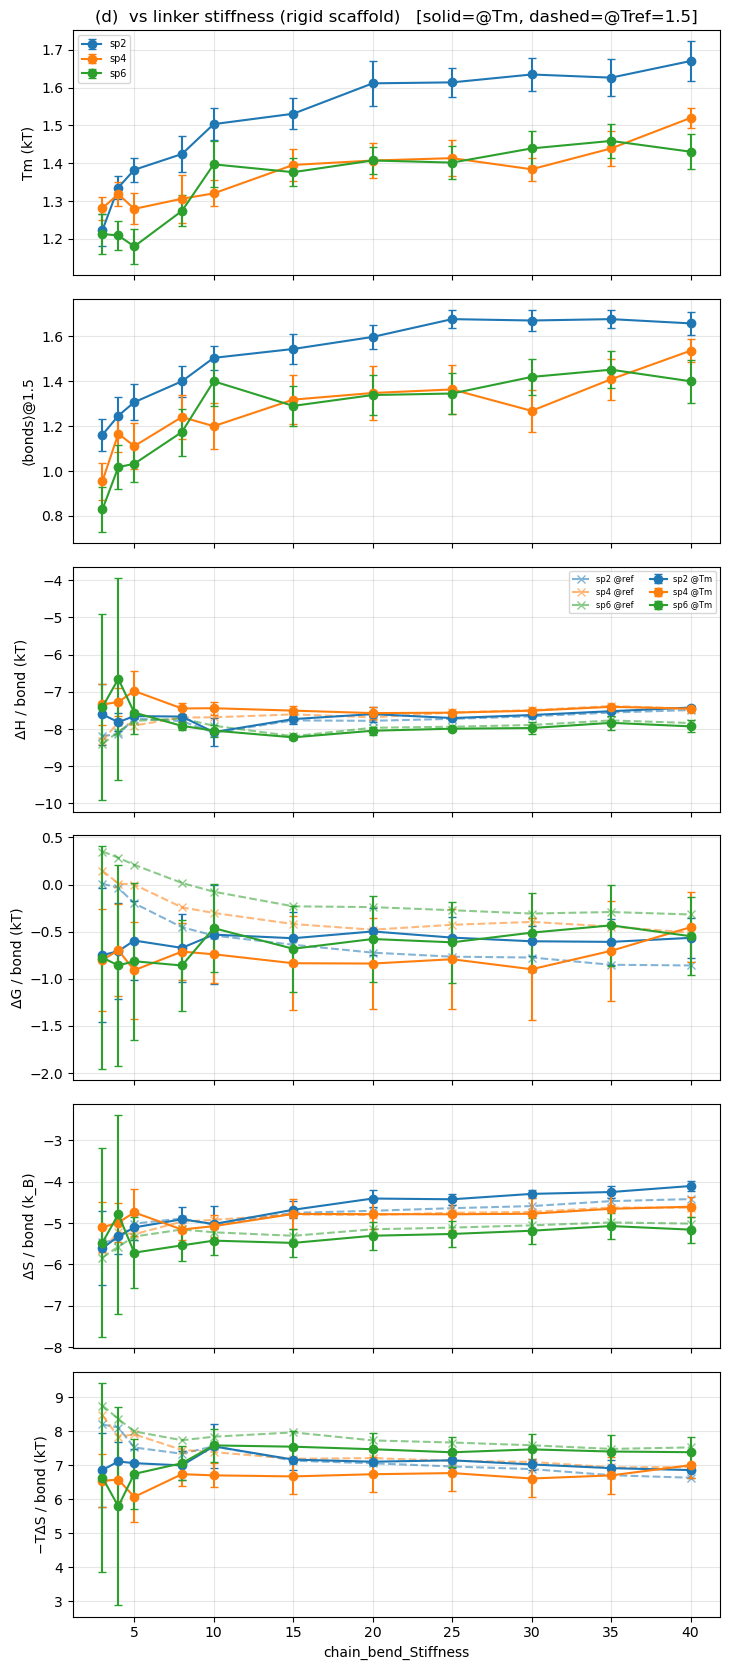

  (d) saved (33 rows)  @Tm + @ref


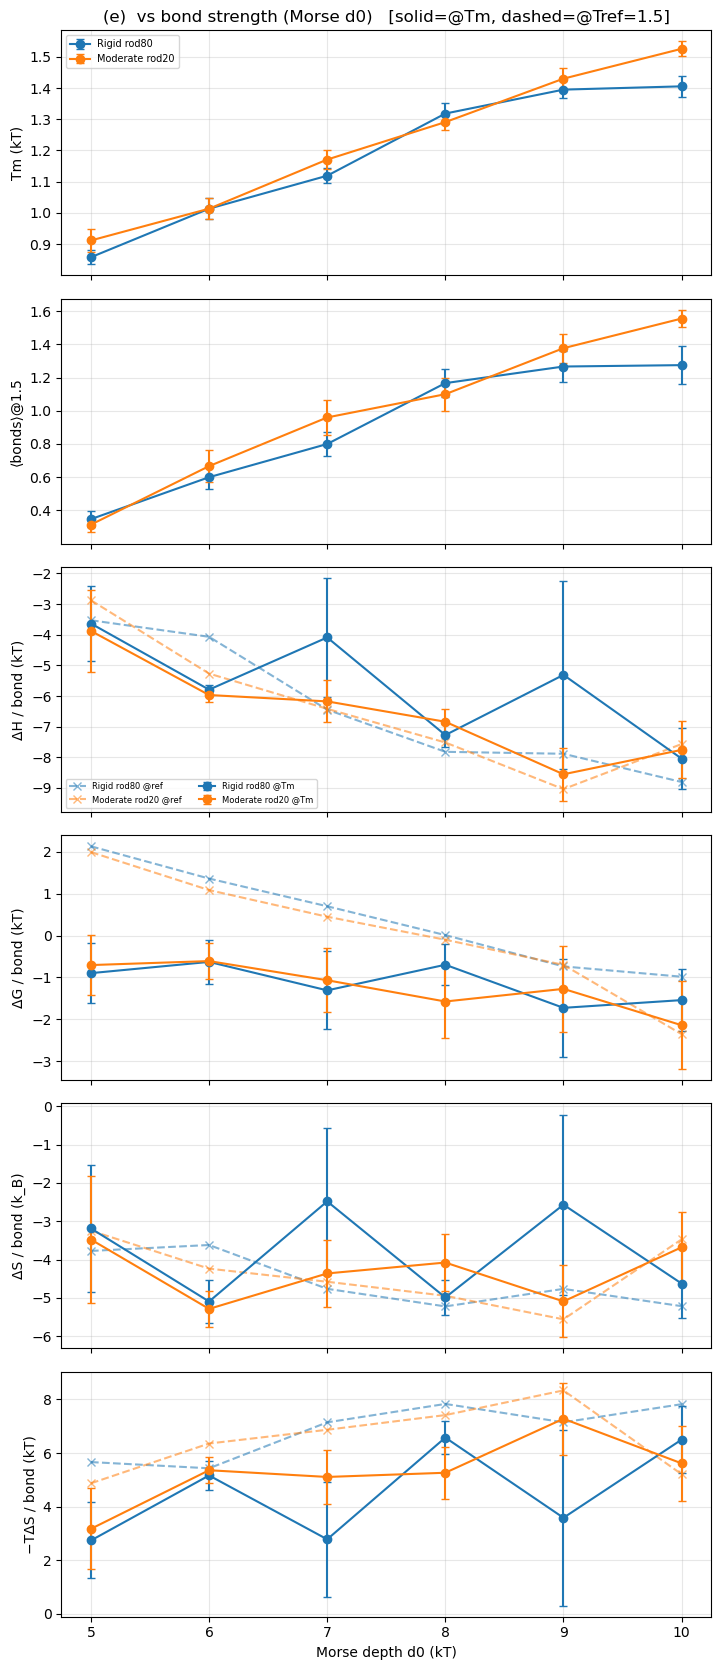

  (e) saved (12 rows)  @Tm + @ref


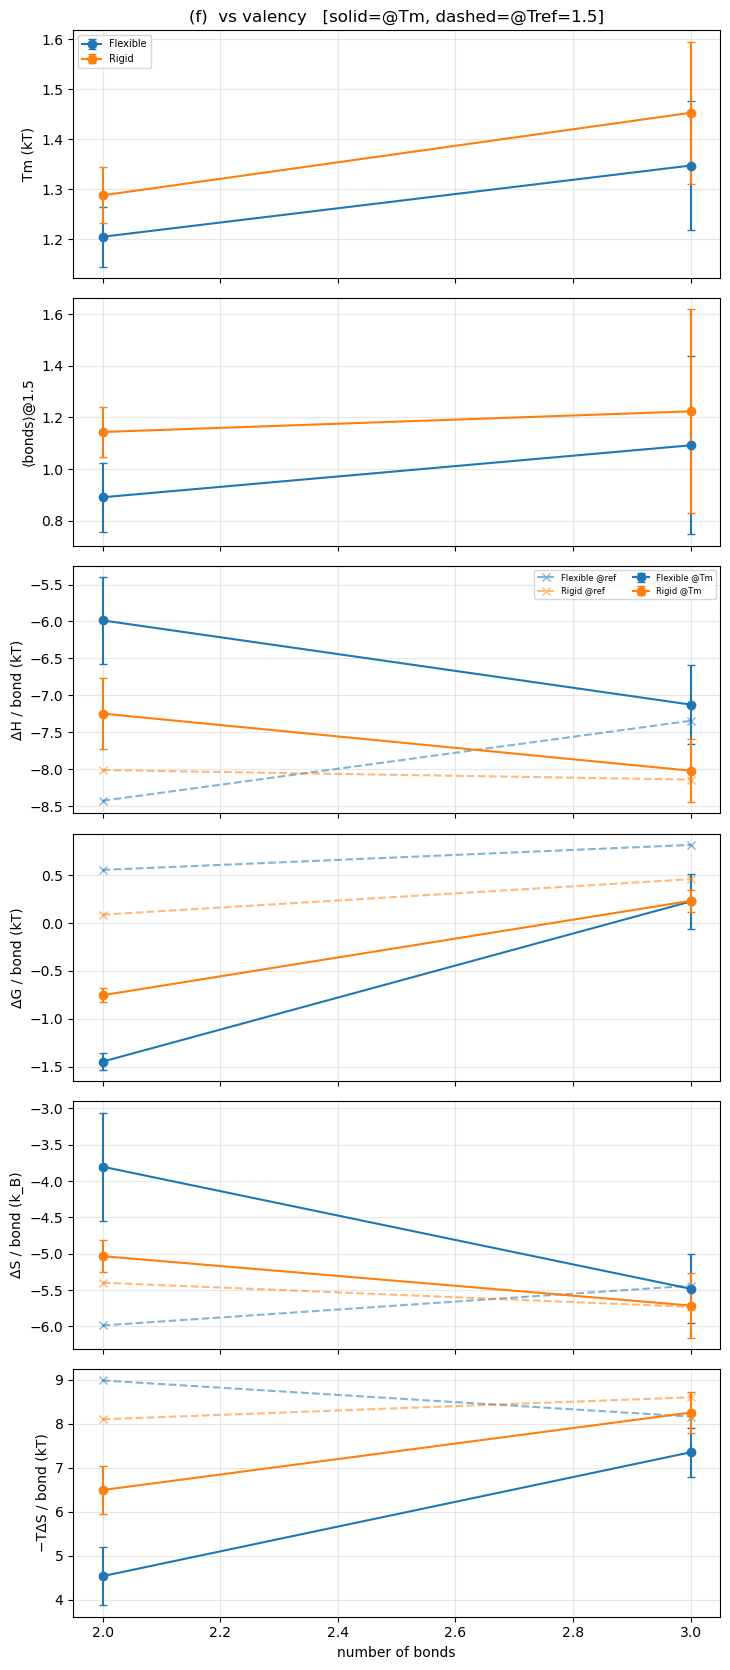

  (f) saved (4 rows)  @Tm + @ref
done: per-bond dH/dG/dS @Tm (solid) and @Tref (dashed) -> plots_robust/{b..f}/


In [8]:
# ===== b–f panels regenerated on the v2 rerun data (std_results_v2 -> plots_robust_v2) =====
# Non-destructive: original plots_robust/ (old data) left intact for comparison.
import os,re,glob,csv,collections
rng=np.random.default_rng(0)

import numpy as np, glob, re, os, collections
import matplotlib.pyplot as plt
rng = np.random.default_rng(0)

# --- design parameters per notebook stem (scaffold rigidity = rod_bend, linker = chain_bend) ---
PARAMS = {
 "Base": dict(rod=4, chain=4, edge=False, nb3=False),
 "FlexScaffold3bonds": dict(rod=4, chain=4, edge=False, nb3=True),
 "FlexScaffold3bonds_Edge": dict(rod=4, chain=4, edge=True, nb3=True),
 "ModerateScaffold": dict(rod=20, chain=4, edge=False, nb3=False),
 "ModerateScaffold_Energy": dict(rod=20, chain=4, edge=False, nb3=False),
 "ModerateScaffold_Spacing": dict(rod=20, chain=4, edge=False, nb3=False),
 "RigidScaffold": dict(rod=80, chain=4, edge=False, nb3=False),
 "RigidScaffold3bonds": dict(rod=80, chain=4, edge=False, nb3=True),
 "RigidScaffold3bonds_Edge": dict(rod=80, chain=4, edge=True, nb3=True),
 "RigidScaffold_Energy": dict(rod=80, chain=4, edge=False, nb3=False),
 "RigidScaffold_Less3ModerateChain": dict(rod=80, chain=3, edge=False, nb3=False),
 "RigidScaffold_Less4ModerateChain": dict(rod=80, chain=4, edge=False, nb3=False),
 "RigidScaffold_Less5ModerateChain": dict(rod=80, chain=5, edge=False, nb3=False),
 "RigidScaffold_Less8ModerateChain": dict(rod=80, chain=8, edge=False, nb3=False),
 "RigidScaffold_LessModerateChain": dict(rod=80, chain=10, edge=False, nb3=False),
 "RigidScaffold_Moderate15Chain": dict(rod=80, chain=15, edge=False, nb3=False),
 "RigidScaffold_Moderate25Chain": dict(rod=80, chain=25, edge=False, nb3=False),
 "RigidScaffold_Moderate30Chain": dict(rod=80, chain=30, edge=False, nb3=False),
 "RigidScaffold_Moderate35Chain": dict(rod=80, chain=35, edge=False, nb3=False),
 "RigidScaffold_ModerateChain": dict(rod=80, chain=20, edge=False, nb3=False),
 "RigidScaffold_RigidChain": dict(rod=80, chain=40, edge=False, nb3=False),
 "RigidScaffold_Spacing": dict(rod=80, chain=4, edge=False, nb3=False),
 "VeryRigidScaffold": dict(rod=240, chain=4, edge=False, nb3=False),
}

PAT = re.compile(r"std_(?P<stem>.+?)_sp(?P<sp>\d+)(?:_d0(?P<d0>\d+))?_rep\d+_seed\d+\.npz$")

def stat_ineff(x):
    x = np.asarray(x, float); N = x.size
    if N < 3: return 1.0
    dx = x - x.mean(); v = np.mean(dx*dx)
    if v <= 1e-12: return 1.0
    g = 1.0
    for t in range(1, N-1):
        c = np.sum(dx[:N-t]*dx[t:]) / ((N-t)*v)
        if c <= 0: break
        g += 2*(1-t/N)*c
    return max(g, 1.0)

# interface key (stem, sp, d0) -> {T: pooled independent samples across replicates}
IFACE = collections.defaultdict(lambda: collections.defaultdict(list))
for f in sorted(glob.glob("std_results_v2/*.npz")):
    m = PAT.search(os.path.basename(f))
    if not m: continue
    try:
        d = np.load(f, allow_pickle=True); T = np.asarray(d["temperatures"], float)
        nb = d["nbound"]; cr = np.asarray(d["crashed"])
    except Exception:
        continue
    key = (m["stem"], int(m["sp"]), int(m["d0"]) if m["d0"] else None)
    for i in range(len(T)):
        if cr[i]: continue
        s = np.asarray(nb[i], float)
        if s.size < 10: continue
        stride = max(1, int(round(stat_ineff(s))))
        IFACE[key][float(T[i])].extend(s[::stride].tolist())

def curve(key):
    Ts = np.array(sorted(IFACE[key])); B = np.array([np.mean(IFACE[key][t]) for t in Ts])
    return Ts, B

def Tm(key, boot=300):
    Ts, B = curve(key)
    half = 1.5 if PARAMS.get(key[0], {}).get("nb3", False) else 1.0   # melting midpoint = n_max/2 (3-bond->1.5, 2-bond->1.0)
    if Ts.size < 2 or not (B.min() <= half <= B.max()): return None
    def cross(bv):
        for i in range(len(Ts)-1):
            if (bv[i]-half)*(bv[i+1]-half) <= 0 and bv[i] != bv[i+1]:
                return Ts[i] + (half-bv[i])*(Ts[i+1]-Ts[i])/(bv[i+1]-bv[i])
        return np.nan
    t0 = cross(B)
    bs = [cross(np.array([np.mean(rng.choice(IFACE[key][t], len(IFACE[key][t]), replace=True)) for t in Ts]))
          for _ in range(boot)]
    bs = [b for b in bs if np.isfinite(b)]
    return (float(t0), float(np.std(bs)) if bs else np.nan)

TM = {k: Tm(k) for k in IFACE}
TM = {k: v for k, v in TM.items() if v}
print(f"loaded {len(IFACE)} interfaces; {len(TM)} have a crossable Tm")



fig, ax = plt.subplots(2, 2, figsize=(13, 10))
# A) spacing, 3-bond families
famA = [("FlexScaffold3bonds","Flex center","tab:blue","o"),
        ("RigidScaffold3bonds","Rigid center","tab:red","o")]
for stem, lab, c, mk in famA:
    pts = sorted((sp, TM[(stem,sp,None)]) for (st,sp,d0) in TM if st==stem and d0 is None)
    if not pts: continue
    xs=[p[0] for p in pts]; ys=[p[1][0] for p in pts]; es=[p[1][1] for p in pts]
    ax[0,0].errorbar(xs, ys, yerr=es, marker=mk, color=c, label=lab, capsize=3, lw=1.6)
ax[0,0].set_title("A. Tm vs bond spacing (3-bond)"); ax[0,0].set_xlabel("bond spacing"); ax[0,0].set_ylabel("Tm (kT)")
ax[0,0].legend(fontsize=8); ax[0,0].grid(alpha=.3)
# B) scaffold rigidity (2-bond center, chain=4)
rig = [("Base",4),("ModerateScaffold",20),
       ("RigidScaffold",80),("VeryRigidScaffold",240)]
for spc, ls in [(2,'--'),(4,'-'),(6,'-.')]:
    xy=[(rod,)+TM[(s,spc,None)] for s,rod in rig if (s,spc,None) in TM]
    if len(xy)>=2:
        xy.sort(); ax[0,1].errorbar([a[0] for a in xy],[a[1] for a in xy],yerr=[a[2] for a in xy],
                                    marker='o', ls=ls, capsize=3, label=f"sp={spc}")
ax[0,1].set_xscale('log'); ax[0,1].set_title("B. Tm vs scaffold rigidity  (ladder-limited)")
ax[0,1].set_xlabel("rod_bend_Stiffness (log)"); ax[0,1].set_ylabel("Tm (kT)"); ax[0,1].legend(fontsize=8); ax[0,1].grid(alpha=.3)
# C) chain/linker stiffness (rigid scaffold rod=80, 2-bond)
chain_s = {s:PARAMS[s]["chain"] for s in PARAMS if PARAMS[s]["rod"]==80 and not PARAMS[s]["nb3"] and "Chain" in s}
for spc, ls, c in [(2,'--','tab:purple'),(4,'-','tab:green'),(6,'-.','tab:brown')]:
    xy=[(ch,)+TM[(s,spc,None)] for s,ch in chain_s.items() if (s,spc,None) in TM]
    if len(xy)>=2:
        xy.sort(); ax[1,0].errorbar([a[0] for a in xy],[a[1] for a in xy],yerr=[a[2] for a in xy],
                                    marker='D', ls=ls, color=c, capsize=3, label=f"sp={spc}")
ax[1,0].set_title("C. Tm vs linker stiffness, rigid scaffold  (ladder-limited)")
ax[1,0].set_xlabel("chain_bend_Stiffness"); ax[1,0].set_ylabel("Tm (kT)"); ax[1,0].legend(fontsize=8); ax[1,0].grid(alpha=.3)
# D) bond strength control
for stem, lab, c in [("RigidScaffold_Energy","Rigid (rod80)","tab:red"),
                     ("ModerateScaffold_Energy","Moderate (rod20)","tab:orange")]:
    byd=collections.defaultdict(list)
    for (st,sp,d0) in TM:
        if st==stem and d0 is not None: byd[d0].append(TM[(st,sp,d0)][0])
    if byd:
        xs=sorted(byd); ax[1,1].errorbar(xs,[np.mean(byd[x]) for x in xs],yerr=[np.std(byd[x]) for x in xs],
                                         marker='s', color=c, label=lab, capsize=3)
ax[1,1].set_title("D. CONTROL: Tm vs bond strength d0"); ax[1,1].set_xlabel("Morse depth d0 (kT)")
ax[1,1].set_ylabel("Tm (kT)"); ax[1,1].legend(fontsize=8); ax[1,1].grid(alpha=.3)
fig.suptitle("Metastable-Tm trends across design axes", fontsize=13); fig.tight_layout()
fig.savefig("analysis_trend_panels.png", dpi=135); plt.show()



# interfaces that need an UPWARD ladder extension: B_mean never reaches 1.5 (stays bound) -> melt above ladder top
need_up = []
for key in IFACE:
    Ts, B = curve(key)
    if Ts.size < 2: continue
    half = 1.5 if PARAMS.get(key[0], {}).get("nb3", False) else 1.0
    if B.min() > half:                       # never drops to the melting midpoint (n_max/2)
        need_up.append((key, Ts, B))
need_up.sort(key=lambda x: -x[1].max())     # hottest ladder first

print(f"{len(need_up)} interfaces need UPWARD T-extension (B_mean stays > 1.5 across their whole ladder)\n")
print(f"{'stem':52} {'sp':>3} {'d0':>3} {'Tmax':>5} {'B@Tmax':>7}")
for key, Ts, B in need_up:
    stem, sp, d0 = key
    print(f"  {stem.replace('Base','DMC'):50} {sp:>3} {str(d0):>3} {Ts.max():>5.2f} {B[-1]:>7.2f}")

fig, ax = plt.subplots(figsize=(11, 7))
cmap = plt.cm.turbo(np.linspace(0, 1, max(len(need_up),1)))
for (key, Ts, B), col in zip(need_up, cmap):
    stem, sp, d0 = key
    lab = f"{stem.replace('Base_','').replace('Base','base')} sp{sp}" + (f" d0{d0}" if d0 else "")
    ax.plot(Ts, B, 'o-', color=col, lw=1.3, ms=4, label=lab)
ax.axhline(1.5, color='k', ls='--', lw=1.5, label="melting midpoint (B=1.5)")
ax.set_xlabel("temperature kT"); ax.set_ylabel("B_mean (mean bonds)")
ax.set_title("Melting curves needing UPWARD T-ladder extension\n(all plateau above B=1.5 -> Tm is above the sampled range)")
ax.legend(fontsize=6, ncol=2, loc='upper right'); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig("analysis_need_upward_extension.png", dpi=135); plt.show()



# ===== Panels b-f: per-bond dH/dG/dS evaluated at BOTH the design's Tm and a fixed Tref =====
import os, csv
ROOT="plots_robust_v2"; os.makedirs(ROOT,exist_ok=True); TREF=1.5
CMAP=plt.rcParams['axes.prop_cycle'].by_key()['color']

def bmean_at(key, Tref=TREF, boot=150):
    c=IFACE.get(key,{}); cand=[t for t in c if abs(t-Tref)<0.13]
    if not cand: return None
    t=min(cand,key=lambda x:abs(x-Tref)); s=c[t]
    if len(s)<2: return None
    bs=[np.mean(rng.choice(s,len(s),replace=True)) for _ in range(boot)]
    return float(np.mean(s)), float(np.std(bs))

_POOL=None
def _pool():
    import glob as _glob
    P=collections.defaultdict(lambda: collections.defaultdict(lambda:([],[])))
    for f in _glob.glob('std_results_v2/*.npz'):
        m=PAT.search(os.path.basename(f))
        if not m: continue
        try:
            d=np.load(f,allow_pickle=True); T=np.asarray(d['temperatures'],float)
            nb=d['nbound']; pot=d['potent']; cr=np.asarray(d['crashed'])
        except Exception: continue
        key=(m['stem'],int(m['sp']),int(m['d0']) if m['d0'] else None)
        for i in range(len(T)):
            if cr[i]: continue
            n=np.asarray(nb[i],float); pe=np.asarray(pot[i],float); g=np.isfinite(n)&np.isfinite(pe)
            t=round(float(T[i]),3); P[key][t][0].extend(n[g].tolist()); P[key][t][1].extend(pe[g].tolist())
    return P
_SL={}
def _slopes(key, mn=3):
    global _POOL
    if key in _SL: return _SL[key]
    if _POOL is None: _POOL=_pool()
    perT=_POOL.get(key,{}); Ts=[]; H=[]; G=[]
    for t,(ns,pes) in sorted(perT.items()):
        ns=np.array(ns); pes=np.array(pes); tot=len(ns); xs=[]; U=[]; Gn=[]
        for nv in sorted(set(ns.astype(int))):
            msk=ns==nv
            if msk.sum()>=mn: xs.append(nv); U.append(pes[msk].mean()); Gn.append(-t*np.log(msk.sum()/tot))
        if len(xs)>=2: Ts.append(t); H.append(np.polyfit(xs,U,1)[0]); G.append(np.polyfit(xs,Gn,1)[0])
    _SL[key]=(np.array(Ts),np.array(H),np.array(G)); return _SL[key]
def _eval(key, T):
    Ts,H,G=_slopes(key)
    if len(Ts)<2 or T<Ts.min()-1e-6 or T>Ts.max()+1e-6: return None
    dH=float(np.interp(T,Ts,H)); dG=float(np.interp(T,Ts,G))
    loc=(Ts>=T-0.26)&(Ts<=T+0.26)
    eH=float(np.std(H[loc])) if loc.sum()>1 else (float(np.std(H)) if len(H)>1 else 0.3)
    eG=float(np.std(G[loc])) if loc.sum()>1 else (float(np.std(G)) if len(G)>1 else 0.3)
    return dict(T=float(T),dH=dH,dG=dG,dS=(dH-dG)/T,eH=eH,eG=eG,eS=(eH**2+eG**2)**0.5/T)

def getter(field, mode):
    def g(key):
        if mode=='tm':
            tv=Tm(key)
            if not tv: return None
            e=_eval(key, tv[0])
        else:
            e=_eval(key, TREF)
        if not e: return None
        if field=='mTdS': return (-e['T']*e['dS'], e['T']*e['eS'])
        return (e[field], e['e'+field[1].upper()])
    return g
def _agg(fn,key):
    if isinstance(key,list):
        vals=[fn(k) for k in key]; vals=[v for v in vals if v and np.isfinite(v[0])]
        if not vals: return None
        m=np.mean([v[0] for v in vals]); e=np.std([v[0] for v in vals]) if len(vals)>1 else np.mean([v[1] for v in vals])
        return float(m),float(e)
    return fn(key)

THERMO=[("dH","ΔH / bond (kT)"),("dG","ΔG / bond (kT)"),
        ("dS","ΔS / bond (k_B)"),("mTdS",f"−TΔS / bond (kT)")]

def build_panel(letter,title,xlabel,series,xlog=False):
    folder=os.path.join(ROOT,letter); os.makedirs(folder,exist_ok=True); rows=[]
    nrow=2+len(THERMO)
    fig,ax=plt.subplots(nrow,1,figsize=(7.4,2.8*nrow),sharex=True)
    for si,(lab,pts) in enumerate(series):
        col=CMAP[si%len(CMAP)]
        accT={f:([],[],[]) for f,_ in THERMO}; accR={f:([],[],[]) for f,_ in THERMO}
        xt=[];tm=[];tme=[];xb=[];bm=[];bme=[]
        for x,key in pts:
            tv=_agg(Tm,key); bv=_agg(bmean_at,key)
            if tv: xt.append(x); tm.append(tv[0]); tme.append(tv[1])
            if bv: xb.append(x); bm.append(bv[0]); bme.append(bv[1])
            rowd=dict(panel=letter,series=lab,x=x,Tm=(round(tv[0],4) if tv else ""),bonds=(round(bv[0],4) if bv else ""))
            for f,_y in THERMO:
                vt=_agg(getter(f,'tm'),key); vr=_agg(getter(f,'ref'),key)
                if vt: accT[f][0].append(x); accT[f][1].append(vt[0]); accT[f][2].append(vt[1])
                if vr: accR[f][0].append(x); accR[f][1].append(vr[0]); accR[f][2].append(vr[1])
                rowd[f+"_Tm"]=(round(vt[0],4) if vt else ""); rowd[f+"_ref"]=(round(vr[0],4) if vr else "")
            rows.append(rowd)
        if xt: o=np.argsort(xt); ax[0].errorbar(np.array(xt)[o],np.array(tm)[o],yerr=np.array(tme)[o],marker='o',color=col,capsize=3,label=lab)
        if xb: o=np.argsort(xb); ax[1].errorbar(np.array(xb)[o],np.array(bm)[o],yerr=np.array(bme)[o],marker='o',color=col,capsize=3,label=lab)
        for ri,(f,_y) in enumerate(THERMO):
            xs,vs,es=accT[f]
            if xs: o=np.argsort(xs); ax[2+ri].errorbar(np.array(xs)[o],np.array(vs)[o],yerr=np.array(es)[o],marker='o',ls='-',color=col,capsize=3,label=(lab+" @Tm" if ri==0 else None))
            xs,vs,es=accR[f]
            if xs: o=np.argsort(xs); ax[2+ri].plot(np.array(xs)[o],np.array(vs)[o],marker='x',ls='--',color=col,alpha=.55,label=(lab+" @ref" if ri==0 else None))
    ax[0].set_ylabel("Tm (kT)"); ax[1].set_ylabel(f"⟨bonds⟩@{TREF}")
    for ri,(f,ylab) in enumerate(THERMO): ax[2+ri].set_ylabel(ylab)
    for a in ax:
        a.grid(alpha=.3)
        if xlog: a.set_xscale('log')
    ax[0].set_title(f"({letter})  {title}   [solid=@Tm, dashed=@Tref={TREF}]")
    ax[0].legend(fontsize=7); ax[2].legend(fontsize=6,ncol=2); ax[-1].set_xlabel(xlabel)
    fig.tight_layout(); fig.savefig(os.path.join(folder,f"panel_{letter}.svg")); plt.show()
    fns=["panel","series","x","Tm","bonds"]+sum([[f+"_Tm",f+"_ref"] for f,_ in THERMO],[])
    with open(os.path.join(folder,f"panel_{letter}.csv"),"w",newline="") as fh:
        w=csv.DictWriter(fh,fieldnames=fns,extrasaction='ignore'); w.writeheader(); [w.writerow(r) for r in rows]
    print(f"  ({letter}) saved ({len(rows)} rows)  @Tm + @ref")

SP3=[3,5,7,8,9,10]
build_panel("b","per-bond ΔH/ΔG/ΔS vs bond spacing (3-bond, center only)","bond spacing",[
  ("Flex center",[(sp,("FlexScaffold3bonds",sp,None)) for sp in SP3]),
  ("Rigid center",[(sp,("RigidScaffold3bonds",sp,None)) for sp in SP3])])
rigmap=[(4,"Base"),(20,"ModerateScaffold"),(80,"RigidScaffold"),(240,"VeryRigidScaffold")]
build_panel("c","vs scaffold rigidity","rod_bend_Stiffness (log)",[(f"sp{sp}",[(rod,(stem,sp,None)) for rod,stem in rigmap]) for sp in [2,4,6]],xlog=True)
chmap=sorted((PARAMS[s]["chain"],s) for s in PARAMS if PARAMS[s]["rod"]==80 and not PARAMS[s]["nb3"] and "Chain" in s)
build_panel("d","vs linker stiffness (rigid scaffold)","chain_bend_Stiffness",[(f"sp{sp}",[(ch,(stem,sp,None)) for ch,stem in chmap]) for sp in [2,4,6]])
eser=[]
for stem,lab in [("RigidScaffold_Energy","Rigid rod80"),("ModerateScaffold_Energy","Moderate rod20")]:
    d0s=sorted(set(d0 for (st,sp,d0) in IFACE if st==stem and d0 is not None))
    pts=[(d0,(stem,[sp for (st,sp,dd) in IFACE if st==stem and dd==d0][0],d0)) for d0 in d0s if [sp for (st,sp,dd) in IFACE if st==stem and dd==d0]]
    eser.append((lab,pts))
build_panel("e","vs bond strength (Morse d0)","Morse depth d0 (kT)",eser)
def keys_for(stem): return [(stem,sp,None) for (st,sp,d0) in IFACE if st==stem and d0 is None]
build_panel("f","vs valency","number of bonds",[
  ("Flexible",[(2,keys_for("Base")),(3,keys_for("FlexScaffold3bonds"))]),
  ("Rigid",[(2,keys_for("RigidScaffold")),(3,keys_for("RigidScaffold3bonds"))])])
print("done: per-bond dH/dG/dS @Tm (solid) and @Tref (dashed) -> plots_robust/{b..f}/")

## chain × rod preorganization heatmaps

From the 16-design grid (`grid_results/`, sp4, 2-bond). Tip-gap σ (linker) drops down the chain axis and is ~flat across rod; anchor-spacing σ (scaffold) drops across the rod axis and is flat down chain — the two preorganization mechanisms are orthogonal. Outputs: `plots_robust/mechanism/heatmap_grid.svg` + `heatmap_grid.csv`.

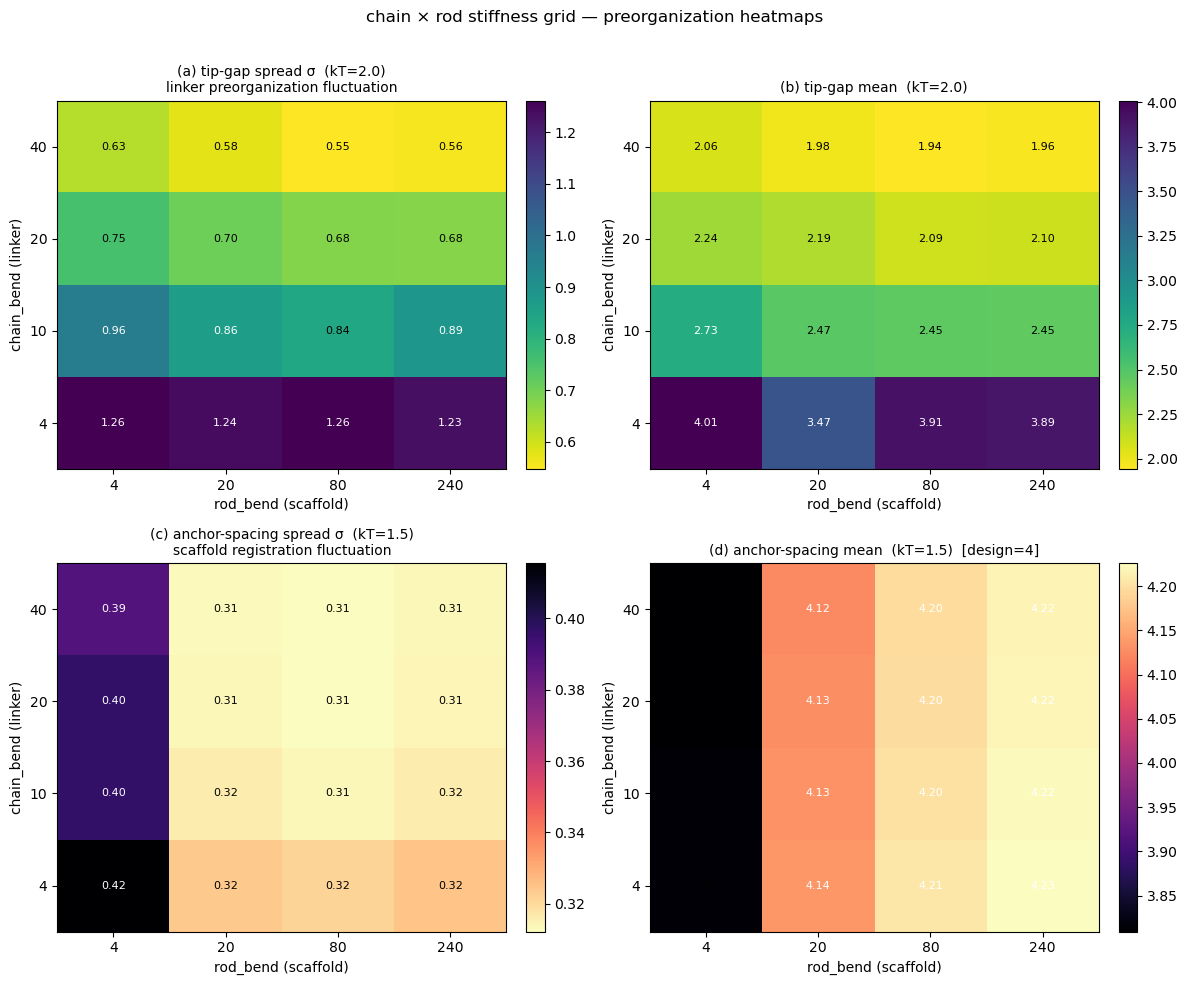

=== tip-gap σ [row=chain, col=rod] @kT=2.0 ===
        rod=     4      20      80     240
chain=  4   1.26    1.24    1.26    1.23
chain= 10   0.96    0.86    0.84    0.89
chain= 20   0.75    0.70    0.68    0.68
chain= 40   0.63    0.58    0.55    0.56

=== anchor-spacing σ [row=chain, col=rod] @kT=1.5 ===
        rod=     4      20      80     240
chain=  4   0.42    0.32    0.32    0.32
chain= 10   0.40    0.32    0.31    0.32
chain= 20   0.40    0.31    0.31    0.31
chain= 40   0.39    0.31    0.31    0.31

saved -> heatmap_grid.svg + heatmap_grid.csv (32 rows)


In [9]:
"""chain x rod heatmaps from the grid GSD trajectories (sp4, 2-bond).
Per (chain_bend, rod_bend, T): tip-gap (unbound tip-tip distance; LINKER preorganization)
and intra-rod anchor spacing (SCAFFOLD registration). Shows whether rod stiffness reduces
tip fluctuation (and whether it interacts with chain), de-confounding panel (d)."""
import os, csv, numpy as np, matplotlib.pyplot as plt
import gsd.hoomd
G = "grid_results"
MROOT = "plots_robust/mechanism"; os.makedirs(MROOT, exist_ok=True)
CHAINS = [4, 10, 20, 40]; RODS = [4, 20, 80, 240]
TIPS = [(46, 52), (49, 55)]           # bridge tip pairs
INTRA = [(9, 13), (31, 35)]           # intra-rod anchor pairs
RBIND = 1.4

def metrics(c, r, T):
    f = os.path.join(G, f"gsd_grid_c{c}_r{r}_T{T:g}.gsd")
    if not os.path.exists(f): return None
    gap = []; spc = []
    t = gsd.hoomd.open(f, "r")
    for fr in t:
        p = np.asarray(fr.particles.position)
        for i, j in TIPS:
            d = np.linalg.norm(p[i] - p[j])
            if d > RBIND: gap.append(d)          # unbound tip-tip gap
        for a, b in INTRA: spc.append(np.linalg.norm(p[a] - p[b]))
    t.close()
    gap = np.array(gap); spc = np.array(spc)
    return dict(gap_mean=gap.mean() if len(gap) else np.nan,
                gap_sig=gap.std() if len(gap) > 1 else np.nan, gap_n=len(gap),
                spc_mean=spc.mean(), spc_sig=spc.std())

# build matrices  [row=chain, col=rod]
T_TIP, T_REG = 2.0, 1.5
GAPsig = np.full((4, 4), np.nan); GAPmean = np.full((4, 4), np.nan)
REGsig = np.full((4, 4), np.nan); REGmean = np.full((4, 4), np.nan)
rows = []
for ci, c in enumerate(CHAINS):
    for ri, r in enumerate(RODS):
        mt = metrics(c, r, T_TIP); mr = metrics(c, r, T_REG)
        if mt: GAPsig[ci, ri] = mt["gap_sig"]; GAPmean[ci, ri] = mt["gap_mean"]
        if mr: REGsig[ci, ri] = mr["spc_sig"]; REGmean[ci, ri] = mr["spc_mean"]
        for T, m in ((T_TIP, mt), (T_REG, mr)):
            if m: rows.append([c, r, T, round(m["gap_mean"],4), round(m["gap_sig"],4),
                               m["gap_n"], round(m["spc_mean"],4), round(m["spc_sig"],4)])

def heat(ax, M, title, cmap, fmt="{:.2f}"):
    im = ax.imshow(M, origin="lower", cmap=cmap, aspect="auto")
    ax.set_xticks(range(4)); ax.set_xticklabels(RODS); ax.set_yticks(range(4)); ax.set_yticklabels(CHAINS)
    ax.set_xlabel("rod_bend (scaffold)"); ax.set_ylabel("chain_bend (linker)")
    ax.set_title(title, fontsize=10)
    for i in range(4):
        for j in range(4):
            if np.isfinite(M[i, j]):
                ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center",
                        color="white" if (M[i, j] > np.nanmean(M)) else "black", fontsize=8)
    plt.colorbar(im, ax=ax, fraction=.046, pad=.04)

fig, ax = plt.subplots(2, 2, figsize=(12, 10))
heat(ax[0, 0], GAPsig, f"(a) tip-gap spread σ  (kT={T_TIP})\nlinker preorganization fluctuation", "viridis_r")
heat(ax[0, 1], GAPmean, f"(b) tip-gap mean  (kT={T_TIP})", "viridis_r")
heat(ax[1, 0], REGsig, f"(c) anchor-spacing spread σ  (kT={T_REG})\nscaffold registration fluctuation", "magma_r")
heat(ax[1, 1], REGmean, f"(d) anchor-spacing mean  (kT={T_REG})  [design=4]", "magma")
fig.suptitle("chain × rod stiffness grid — preorganization heatmaps", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.97]); fig.savefig(os.path.join(MROOT, "heatmap_grid.svg")); plt.show()

with open(os.path.join(MROOT, "heatmap_grid.csv"), "w", newline="") as fh:
    w = csv.writer(fh); w.writerow(["chain_bend", "rod_bend", "temperature",
        "tipgap_mean", "tipgap_sigma", "tipgap_n_unbound", "anchorspacing_mean", "anchorspacing_sigma"])
    w.writerows(rows)

print("=== tip-gap σ [row=chain, col=rod] @kT=2.0 ===")
print("        rod=" + "  ".join(f"{r:>6}" for r in RODS))
for ci, c in enumerate(CHAINS): print(f"chain={c:>3} " + "  ".join(f"{GAPsig[ci,ri]:6.2f}" for ri in range(4)))
print("\n=== anchor-spacing σ [row=chain, col=rod] @kT=1.5 ===")
print("        rod=" + "  ".join(f"{r:>6}" for r in RODS))
for ci, c in enumerate(CHAINS): print(f"chain={c:>3} " + "  ".join(f"{REGsig[ci,ri]:6.2f}" for ri in range(4)))
print(f"\nsaved -> heatmap_grid.svg + heatmap_grid.csv ({len(rows)} rows)")


## Per-replicate raw values behind the v2 panel error bars

For every b–f panel point, the SAME quantities the panel plots (Tm, ⟨bonds⟩@ref, per-bond ΔH/ΔG/ΔS at Tm and ref) recomputed using each replicate (seed 11/22/33) separately — the raw per-replicate numbers whose spread gives the error bar. Written as `plots_robust_v2/<letter>/panel_<letter>_replicates.csv` (one row per point-key × seed).

In [10]:
# ===== per-REPLICATE raw values behind each v2 panel point (spread = error bar) =====
# Reuses IFACE/PARAMS/stat_ineff from the v2 panel cell above (std_results_v2).
# One row per (panel point key, seed): that replicate's Tm, <bonds>@ref, dH/dG/dS at Tm & ref.
import csv as _csv
"""Per-REPLICATE raw values behind each v2 panel point (the numbers whose spread is the
error bar). For every panel point's interface key and each seed (11/22/33) separately,
recompute the SAME quantities the panels plot -- Tm, <bonds>@ref, and per-bond dH/dG/dS at
Tm and at ref -- using only that replicate's samples and the notebook's own methodology
(stat_ineff decorrelation, 1.5-crossing, population slopes). One row per (point-key, seed).
Output: plots_robust_v2/<letter>/panel_<letter>_replicates.csv."""
import os, re, csv, glob, json, collections, numpy as np
PROJ = os.getcwd()   # self-contained: resolve data relative to this folder
RES = "std_results_v2"; TREF = 1.5
PAT = re.compile(r"std_(?P<stem>.+?)_sp(?P<sp>\d+)(?:_d0(?P<d0>\d+))?_rep(?P<rep>\d+)_seed(?P<seed>\d+)\.npz$")


# ---- per-seed recomputation of the plotted quantities ----
def seed_file(stem, sp, d0, seed):
    pat = f"{RES}/std_{stem}_sp{sp}" + (f"_d0{d0}" if d0 is not None else "") + f"_rep*_seed{seed}.npz"
    for f in glob.glob(pat):
        m = PAT.search(os.path.basename(f))
        if m and m["stem"] == stem and int(m["sp"]) == sp and ((m["d0"] is None and d0 is None) or (m["d0"] and int(m["d0"]) == d0)):
            return f
    return None

def slopes_at(Ts, Hs, Gs, Tq):
    if len(Ts) < 2 or Tq is None or not np.isfinite(Tq): return (np.nan, np.nan, np.nan)
    Ts = np.array(Ts)
    if Tq < Ts.min() - 1e-6 or Tq > Ts.max() + 1e-6: return (np.nan, np.nan, np.nan)
    dH = float(np.interp(Tq, Ts, Hs)); dG = float(np.interp(Tq, Ts, Gs))
    return (dH, dG, (dH - dG) / Tq)

def per_seed(stem, sp, d0, seed, mn=3):
    f = seed_file(stem, sp, d0, seed)
    if not f: return None
    d = np.load(f, allow_pickle=True); T = np.asarray(d["temperatures"], float)
    nb = d["nbound"]; pe = d["potent"]; cr = np.asarray(d["crashed"])
    Ts = []; B = []; Tsl = []; H = []; G = []
    for i in range(len(T)):
        if cr[i]: continue
        s = np.asarray(nb[i], float); p = np.asarray(pe[i], float)
        ok = np.isfinite(s)
        if ok.sum() < 10: continue
        Ts.append(float(T[i])); B.append(float(np.mean(s[ok])))
        n = s[ok]; u = p[ok]; tot = len(n); xs = []; Us = []; Gn = []
        for nv in sorted(set(n.astype(int))):
            msk = n == nv
            if msk.sum() >= mn:
                xs.append(nv); Us.append(u[msk].mean()); Gn.append(-float(T[i]) * np.log(msk.sum() / tot))
        if len(xs) >= 2:
            Tsl.append(float(T[i])); H.append(np.polyfit(xs, Us, 1)[0]); G.append(np.polyfit(xs, Gn, 1)[0])
    if len(Ts) < 2: return None
    Ts = np.array(Ts); B = np.array(B); o = np.argsort(Ts); Ts = Ts[o]; B = B[o]
    # Tm = 1.5 crossing of this replicate's B(T)
    tm = np.nan
    if B.min() <= 1.5 <= B.max():
        for i in range(len(Ts) - 1):
            if (B[i] - 1.5) * (B[i + 1] - 1.5) <= 0 and B[i] != B[i + 1]:
                tm = Ts[i] + (1.5 - B[i]) * (Ts[i + 1] - Ts[i]) / (B[i + 1] - B[i]); break
    bonds_ref = float(B[np.argmin(np.abs(Ts - TREF))]) if len(Ts) else np.nan
    Tsl = np.array(Tsl); so = np.argsort(Tsl); Tsl = Tsl[so]; H = np.array(H)[so]; G = np.array(G)[so]
    dH_tm, dG_tm, dS_tm = slopes_at(Tsl, H, G, tm)
    dH_rf, dG_rf, dS_rf = slopes_at(Tsl, H, G, TREF)
    return dict(Tm=tm, bonds_ref=bonds_ref, dH_Tm=dH_tm, dH_ref=dH_rf,
                dG_Tm=dG_tm, dG_ref=dG_rf, dS_Tm=dS_tm, dS_ref=dS_rf)

# ---- panel -> (series, x, [keys]) exactly as build_panel is called ----
SP3 = [3, 5, 7, 8, 9, 10]
panels = {}
panels["b"] = [(lab, [(sp, [(stem, sp, None)]) for sp in SP3]) for lab, stem in [
    ("Flex center", "FlexScaffold3bonds"),
    ("Rigid center", "RigidScaffold3bonds")]]
rigmap = [(4, "Base"), (20, "ModerateScaffold"),
          (80, "RigidScaffold"), (240, "VeryRigidScaffold")]
panels["c"] = [(f"sp{sp}", [(rod, [(stem, sp, None)]) for rod, stem in rigmap]) for sp in [2, 4, 6]]
chmap = sorted((PARAMS[s]["chain"], s) for s in PARAMS if PARAMS[s]["rod"] == 80 and not PARAMS[s]["nb3"] and "Chain" in s)
panels["d"] = [(f"sp{sp}", [(ch, [(stem, sp, None)]) for ch, stem in chmap]) for sp in [2, 4, 6]]
eser = []
for stem in ["RigidScaffold_Energy", "ModerateScaffold_Energy"]:
    d0s = sorted(set(d0 for (st, sp, d0) in IFACE if st == stem and d0 is not None))
    pts = [(d0, [(stem, [sp for (st, sp, dd) in IFACE if st == stem and dd == d0][0], d0)])
           for d0 in d0s if [sp for (st, sp, dd) in IFACE if st == stem and dd == d0]]
    eser.append((stem, pts))
panels["e"] = eser
def keys_for(stem): return [(stem, sp, None) for (st, sp, d0) in IFACE if st == stem and d0 is None]
panels["f"] = [("Flexible", [(2, keys_for("Base")), (3, keys_for("FlexScaffold3bonds"))]),
               ("Rigid", [(2, keys_for("RigidScaffold")), (3, keys_for("RigidScaffold3bonds"))])]

SEEDS = [11, 22, 33]
FIELDS = ["Tm", "bonds_ref", "dH_Tm", "dH_ref", "dG_Tm", "dG_ref", "dS_Tm", "dS_ref"]
for letter, series in panels.items():
    folder = os.path.join("plots_robust_v2", letter); os.makedirs(folder, exist_ok=True)
    n = 0
    with open(os.path.join(folder, f"panel_{letter}_replicates.csv"), "w", newline="") as fh:
        w = csv.writer(fh); w.writerow(["panel", "series", "x", "stem", "spacing", "d0", "seed"] + FIELDS)
        for lab, pts in series:
            for x, keys in pts:
                for (stem, sp, d0) in keys:
                    for seed in SEEDS:
                        r = per_seed(stem, sp, d0, seed)
                        if not r: continue
                        w.writerow([letter, lab, x, stem, sp, ("" if d0 is None else d0), seed] +
                                   [("" if not np.isfinite(r[k]) else round(r[k], 5)) for k in FIELDS])
                        n += 1
    print(f"  panel {letter}: {n} replicate rows -> {folder}/panel_{letter}_replicates.csv")
print("done")


  panel b: 72 replicate rows -> plots_robust_v2/b/panel_b_replicates.csv


  panel c: 36 replicate rows -> plots_robust_v2/c/panel_c_replicates.csv


  panel d: 99 replicate rows -> plots_robust_v2/d/panel_d_replicates.csv


  panel e: 36 replicate rows -> plots_robust_v2/e/panel_e_replicates.csv
  panel f: 60 replicate rows -> plots_robust_v2/f/panel_f_replicates.csv
done


## Panel F (corrected): valency at MATCHED adjacent spacing s=4

The original panel F averaged each valency over its family's whole spacing set, which were **non-overlapping** (2-bond s∈{2,4,6}, 3-bond s∈{3,5,7,8,9,10}), confounding valency with spacing. The 3-bond interfaces were therefore re-run at **s=4** under the identical protocol so 2-bond and 3-bond are compared at the same adjacent graft-site gap. Result: adding the 3rd bond raises Tm by ~0.3 kT in both families (Flexible 1.11→1.44, Rigid 1.23→1.51), with no spacing confound. Outputs: `plots_robust_v2/f_matched/panel_f_matched.svg` + `_summary.csv` + `_replicates.csv`.

In [11]:
"""Panel F, corrected: valency (2 vs 3 bonds) at MATCHED adjacent spacing s=4.
2-bond s=4 already existed; the 3-bond interfaces were just run at s=4 under the identical
protocol. For each of the 4 keys (Flexible/Rigid x 2/3-bond, all sp4), recompute per
replicate (seed) the same quantities the panels plot (Tm, <bonds>@ref, per-bond dH/dG/dS at
Tm & ref), then plot 2 vs 3 with replicate error bars (mean +/- s.d. over seeds)."""
import os, re, csv, glob, numpy as np, matplotlib
matplotlib.use("Agg"); import matplotlib.pyplot as plt
PROJ = os.getcwd()   # self-contained: resolve data relative to this folder
RES = "std_results_v2"; TREF = 1.5; SEEDS = [11, 22, 33]
OUT = os.path.join("plots_robust_v2", "f_matched"); os.makedirs(OUT, exist_ok=True)
PAT = re.compile(r"std_(?P<stem>.+?)_sp(?P<sp>\d+)(?:_d0(?P<d0>\d+))?_rep(?P<rep>\d+)_seed(?P<seed>\d+)\.npz$")

def seed_file(stem, sp, seed):
    for f in glob.glob(f"{RES}/std_{stem}_sp{sp}_rep*_seed{seed}.npz"):
        m = PAT.search(os.path.basename(f))
        if m and m["stem"] == stem and int(m["sp"]) == sp and m["d0"] is None:
            return f
    return None

def slopes_at(Ts, H, G, Tq):
    if len(Ts) < 2 or Tq is None or not np.isfinite(Tq): return (np.nan,)*3
    Ts = np.array(Ts)
    if Tq < Ts.min()-1e-6 or Tq > Ts.max()+1e-6: return (np.nan,)*3
    dH = float(np.interp(Tq, Ts, H)); dG = float(np.interp(Tq, Ts, G))
    return dH, dG, (dH-dG)/Tq

def per_seed(stem, sp, seed, mn=3):
    f = seed_file(stem, sp, seed)
    if not f: return None
    d = np.load(f, allow_pickle=True); T = np.asarray(d["temperatures"], float)
    nb = d["nbound"]; pe = d["potent"]; cr = np.asarray(d["crashed"])
    Ts=[]; B=[]; Tsl=[]; H=[]; G=[]
    for i in range(len(T)):
        if cr[i]: continue
        s = np.asarray(nb[i], float); p = np.asarray(pe[i], float); ok = np.isfinite(s)
        if ok.sum() < 10: continue
        Ts.append(float(T[i])); B.append(float(np.mean(s[ok])))
        n = s[ok]; u = p[ok]; tot = len(n); xs=[]; Us=[]; Gn=[]
        for nv in sorted(set(n.astype(int))):
            m = n == nv
            if m.sum() >= mn: xs.append(nv); Us.append(u[m].mean()); Gn.append(-float(T[i])*np.log(m.sum()/tot))
        if len(xs) >= 2:
            Tsl.append(float(T[i])); H.append(np.polyfit(xs,Us,1)[0]); G.append(np.polyfit(xs,Gn,1)[0])
    if len(Ts) < 2: return None
    Ts=np.array(Ts); B=np.array(B); o=np.argsort(Ts); Ts=Ts[o]; B=B[o]
    tm=np.nan
    if B.min() <= 1.5 <= B.max():
        for i in range(len(Ts)-1):
            if (B[i]-1.5)*(B[i+1]-1.5) <= 0 and B[i]!=B[i+1]:
                tm = Ts[i]+(1.5-B[i])*(Ts[i+1]-Ts[i])/(B[i+1]-B[i]); break
    bonds = float(B[np.argmin(np.abs(Ts-TREF))])
    Tsl=np.array(Tsl); so=np.argsort(Tsl); Tsl=Tsl[so]; H=np.array(H)[so]; G=np.array(G)[so]
    dH_t,dG_t,dS_t = slopes_at(Tsl,H,G,tm); dH_r,dG_r,dS_r = slopes_at(Tsl,H,G,TREF)
    return dict(Tm=tm, bonds_ref=bonds, dH_Tm=dH_t, dH_ref=dH_r, dG_Tm=dG_t, dG_ref=dG_r, dS_Tm=dS_t, dS_ref=dS_r)

FAMILIES = [("Flexible", {2: "Base", 3: "FlexScaffold3bonds"}),
            ("Rigid",    {2: "RigidScaffold", 3: "RigidScaffold3bonds"})]
FIELDS = ["Tm","bonds_ref","dH_Tm","dH_ref","dG_Tm","dG_ref","dS_Tm","dS_ref"]

# gather per-replicate + aggregate
rep_rows=[]; agg={}
for fam, vmap in FAMILIES:
    for val, stem in vmap.items():
        vals={k:[] for k in FIELDS}
        for seed in SEEDS:
            r = per_seed(stem, 4, seed)
            if not r: continue
            rep_rows.append([fam, val, stem, seed] + [("" if not np.isfinite(r[k]) else round(r[k],5)) for k in FIELDS])
            for k in FIELDS:
                if np.isfinite(r[k]): vals[k].append(r[k])
        agg[(fam,val)] = {k:(np.mean(v), np.std(v), len(v)) for k,v in vals.items() if v}

# figure: Tm, bonds, dH, dG, dS (at Tm) vs valency, two families
PLOT=[("Tm","Tm (kT)"),("bonds_ref",f"⟨bonds⟩ @ {TREF}"),("dH_Tm","ΔH/bond @Tm (kT)"),
      ("dG_Tm","ΔG/bond @Tm (kT)"),("dS_Tm","ΔS/bond @Tm (k_B)")]
fig, ax = plt.subplots(1, len(PLOT), figsize=(4*len(PLOT), 4))
for fi,(fam,_) in enumerate(FAMILIES):
    col=f"C{fi}"
    for pi,(k,ylab) in enumerate(PLOT):
        xs=[]; ys=[]; es=[]
        for val in (2,3):
            if (fam,val) in agg and k in agg[(fam,val)]:
                m,s,n=agg[(fam,val)][k]; xs.append(val); ys.append(m); es.append(s)
        ax[pi].errorbar(xs, ys, yerr=es, marker="o", capsize=5, color=col, label=fam)
        ax[pi].set_xticks([2,3]); ax[pi].set_xlabel("valency (bonds)"); ax[pi].set_ylabel(ylab)
        ax[pi].grid(alpha=.3)
ax[0].legend(fontsize=9, title="family")
fig.suptitle("Panel F (corrected): valency 2 vs 3 at MATCHED adjacent spacing s=4  (error bars = replicates)", fontsize=11)
fig.tight_layout(rect=[0,0,1,0.95]); fig.savefig(os.path.join(OUT,"panel_f_matched.svg")); plt.show()

# CSVs
with open(os.path.join(OUT,"panel_f_matched_replicates.csv"),"w",newline="") as fh:
    w=csv.writer(fh); w.writerow(["family","valency","stem","seed"]+FIELDS); w.writerows(rep_rows)
with open(os.path.join(OUT,"panel_f_matched_summary.csv"),"w",newline="") as fh:
    w=csv.writer(fh); head=["family","valency","stem","n_rep"]
    for k in FIELDS: head += [k+"_mean", k+"_sd"]
    w.writerow(head)
    for fam,vmap in FAMILIES:
        for val,stem in vmap.items():
            a=agg.get((fam,val),{}); row=[fam,val,stem,(a[FIELDS[0]][2] if FIELDS[0] in a else 0)]
            for k in FIELDS:
                if k in a: row += [round(a[k][0],5), round(a[k][1],5)]
                else: row += ["",""]
            w.writerow(row)

print("=== matched s=4 valency (mean ± sd over seeds) ===")
for fam,vmap in FAMILIES:
    for val in (2,3):
        a=agg.get((fam,val),{})
        if "Tm" in a: print(f"{fam:9s} {val}-bond: Tm={a['Tm'][0]:.3f}±{a['Tm'][1]:.3f}  bonds={a['bonds_ref'][0]:.2f}±{a['bonds_ref'][1]:.2f}  dS_Tm={a['dS_Tm'][0]:.2f}±{a['dS_Tm'][1]:.2f}")
print(f"\nsaved -> {OUT}/panel_f_matched.svg + _summary.csv + _replicates.csv")


=== matched s=4 valency (mean ± sd over seeds) ===
Flexible  2-bond: Tm=1.113±0.102  bonds=0.90±0.10  dS_Tm=-6.22±1.90
Flexible  3-bond: Tm=1.444±0.137  bonds=1.25±0.49  dS_Tm=-5.06±1.11
Rigid     2-bond: Tm=1.232±0.073  bonds=1.00±0.16  dS_Tm=-3.21±2.05
Rigid     3-bond: Tm=1.508±0.159  bonds=1.47±0.34  dS_Tm=-5.38±1.16

saved -> plots_robust_v2/f_matched/panel_f_matched.svg + _summary.csv + _replicates.csv


/var/folders/j7/b00pvk852pndlrr3y6zcy8380000gn/T/ipykernel_1722/1934338467.py:89: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(rect=[0,0,1,0.95]); fig.savefig(os.path.join(OUT,"panel_f_matched.svg")); plt.show()
